# 03 — Mars connected regions and process candidates

**Purpose:** turn the prepared 1° and 10° Mars cells into connected, internally similar regions; discover recurring neutral region types; detect unusual regions; and evaluate conservative process/environment evidence recipes.

This notebook deliberately separates three statements:

1. **Measured region:** neighboring cells have similar properties.
2. **Neutral type:** several regions share a recurring property combination.
3. **Process candidate:** that combination is consistent with a literature-backed interpretation, but may still need detailed imagery or spectroscopy.

It never calls a static surface "active" and never turns hydrogen-sensitive neutron counts into confirmed water ice.

## What to inspect after the run

The useful outputs are:

- The connected-region boundary map: did segmentation create coherent areas rather than scattered pixels?
- The model-comparison plot: are cluster types stable across geographic holdouts?
- The neutral-type map and profile heatmap: what combinations were discovered without process labels?
- The artifact and feature-ablation plots: do coverage stripes or one correlated measurement family control the answer?
- The anomaly map: which regions are unusual and deserve inspection?
- The process-evidence table: which interpretations are supported, ambiguous, or missing required evidence?

CPUs are sufficient. A GPU does not improve the methods used here.

In [1]:
from __future__ import annotations

import importlib.metadata
import json
import math
import re
import warnings
from collections import defaultdict
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Callable

from packaging.version import Version

REQUIRED_DISTRIBUTIONS = {
    "pyarrow": Version("14"),
    "rasterio": Version("1.3"),
    "scikit-learn": Version("1.3"),
}
missing_or_old: list[str] = []
for distribution, minimum_version in REQUIRED_DISTRIBUTIONS.items():
    try:
        installed_version = Version(importlib.metadata.version(distribution))
    except importlib.metadata.PackageNotFoundError:
        missing_or_old.append(f"{distribution}>={minimum_version} (missing)")
        continue
    if installed_version < minimum_version:
        missing_or_old.append(f"{distribution}>={minimum_version} (found {installed_version})")
if missing_or_old:
    raise RuntimeError(
        "This notebook does not install packages automatically. Use a Kaggle image containing: "
        + ", ".join(missing_or_old)
    )

In [2]:
import joblib
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from rasterio.features import shapes as raster_shapes
from rasterio.transform import from_origin
from scipy import ndimage
from sklearn.cluster import HDBSCAN, KMeans
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import adjusted_rand_score, balanced_accuracy_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

sns.set_theme(context="notebook", style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 140)
pd.set_option("display.width", 180)


@dataclass(frozen=True)
class DiscoveryConfig:
    input_root_override: str | None = None
    mars_radius_km: float = 3396.0
    held_out_fold: int = 4
    minimum_group_coverage: float = 0.98
    medium_segmentation_prototypes: int = 16
    coarse_segmentation_prototypes: int = 8
    medium_smoothing_cells: int = 5
    coarse_smoothing_cells: int = 1
    minimum_medium_region_cells: int = 4
    minimum_coarse_region_cells: int = 1
    small_region_merge_distance_quantile: float = 0.90
    small_region_merge_max_distance: float = 1.50
    small_region_merge_rounds: int = 8
    quality_residualization_alpha: float = 25.0
    maximum_cluster_count: int = 10
    maximum_gmm_cluster_count: int = 8
    minimum_partition_regions: int = 12
    maximum_hdbscan_regions: int = 20_000
    maximum_silhouette_rows: int = 5_000
    anomaly_fraction: float = 0.02
    artifact_warning_balanced_accuracy: float = 0.65
    random_seed: int = 42


CFG = DiscoveryConfig()
RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat()
RNG = np.random.default_rng(CFG.random_seed)

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
KAGGLE_WORKING = Path("/kaggle/working")
OUTPUT_ROOT = KAGGLE_WORKING / "mars_region_discovery" if KAGGLE_WORKING.exists() else Path.cwd() / "outputs" / "mars_region_discovery"
REGION_DIR = OUTPUT_ROOT / "regions"
REPORT_DIR = OUTPUT_ROOT / "reports"
MODEL_DIR = OUTPUT_ROOT / "models"
for directory in (OUTPUT_ROOT, REGION_DIR, REPORT_DIR, MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"scikit-learn: {sklearn.__version__}")
print(f"Output root: {OUTPUT_ROOT}")


scikit-learn: 1.9.1
Output root: C:\Users\ordik\OneDrive\Documents\NASA-HACK\notebooks\outputs\mars_region_discovery


## Locate and validate notebook 01 outputs

In Kaggle, save notebook 01 as a version with outputs and add that version as an input to this notebook. The loader also accepts the same live `/kaggle/working` session and the repository's local `outputs` directory.

In [3]:
def discover_preparation_root(override: str | None = None) -> Path:
    required_relative_paths = [
        Path("processed/mars_cells_input.parquet"),
        Path("reports/feature_schema.csv"),
        Path("reports/run_summary.json"),
    ]
    candidates: list[Path] = []
    if override:
        candidates.append(Path(override).expanduser())
    repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    candidates.extend(
        [
            repo_root,
            repo_root / "notebooks" / "outputs" / "mars_data_preparation",
            Path.cwd() / "outputs" / "mars_data_preparation",
            Path("/kaggle/working/mars_data_preparation"),
        ]
    )
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        for cells_path in kaggle_input.rglob("mars_cells_input.parquet"):
            if cells_path.parent.name == "processed":
                candidates.append(cells_path.parent.parent)

    checked: list[str] = []
    for candidate in candidates:
        candidate = candidate.resolve()
        checked.append(str(candidate))
        if all((candidate / relative).exists() for relative in required_relative_paths):
            return candidate
    raise FileNotFoundError(
        "Could not find notebook 01 outputs. Attach the saved Kaggle output or set "
        f"DiscoveryConfig.input_root_override. Checked: {checked}"
    )


INPUT_ROOT = discover_preparation_root(CFG.input_root_override)
CELLS_PATH = INPUT_ROOT / "processed" / "mars_cells_input.parquet"
FEATURE_SCHEMA_PATH = INPUT_ROOT / "reports" / "feature_schema.csv"
PREPARATION_SUMMARY_PATH = INPUT_ROOT / "reports" / "run_summary.json"

cells_df = pd.read_parquet(CELLS_PATH)
feature_schema_df = pd.read_csv(FEATURE_SCHEMA_PATH)
preparation_summary = json.loads(PREPARATION_SUMMARY_PATH.read_text(encoding="utf-8"))

required_cell_columns = {
    "cell_id",
    "planet",
    "scale",
    "row",
    "column",
    "latitude",
    "longitude",
    "latitude_min",
    "latitude_max",
    "longitude_min",
    "longitude_max",
    "spatial_fold",
    "analysis_cohort",
}
missing_cell_columns = sorted(required_cell_columns - set(cells_df.columns))
if missing_cell_columns:
    raise ValueError(f"Prepared cell table is missing required columns: {missing_cell_columns}")
if cells_df["cell_id"].duplicated().any():
    raise ValueError("Prepared cell identifiers are not unique")
if set(cells_df["planet"].dropna().unique()) != {"Mars"}:
    raise ValueError("This notebook accepts Mars rows only")
if set(cells_df["scale"].dropna().unique()) != {"medium_1deg", "coarse_10deg"}:
    raise ValueError(f"Unexpected scales: {sorted(cells_df['scale'].dropna().unique())}")

if feature_schema_df["active_for_model"].dtype != bool:
    feature_schema_df["active_for_model"] = feature_schema_df["active_for_model"].astype(str).str.lower().eq("true")
active_schema_df = feature_schema_df.loc[feature_schema_df["active_for_model"]].copy()
expected_model_columns = {f"model__{feature}" for feature in active_schema_df["feature"]}
missing_model_columns = sorted(expected_model_columns - set(cells_df.columns))
if missing_model_columns:
    raise ValueError(f"Prepared table is missing active model columns: {missing_model_columns[:10]}")

scale_counts = cells_df.groupby(["scale", "analysis_cohort"], observed=True).size().rename("cell_count").reset_index()
print(f"Input root: {INPUT_ROOT}")
display(scale_counts)


Input root: C:\Users\ordik\OneDrive\Documents\NASA-HACK


,scale,analysis_cohort,cell_count
0,coarse_10deg,full_multimodal_with_neutron,396
1,coarse_10deg,no_thermal_with_neutron,252
2,medium_1deg,full_multimodal,39600
3,medium_1deg,no_thermal,25200


## Build comparable feature matrices

Cells are never compared across scales or incompatible coverage cohorts. Within a cohort, an entire science family is retained only when every active feature in that family is available for at least 98% of cells. A few remaining gaps are filled with that cohort's median; a completely absent instrument family is never median-filled. Cohorts with two usable features from only one family remain available for descriptive region discovery, but every resulting row is marked `limited_feature_evidence` and cannot be presented as strong multi-property evidence.

In [4]:
def grid_shape(frame: pd.DataFrame) -> tuple[int, int]:
    rows = int(frame["row"].max()) + 1
    columns = int(frame["column"].max()) + 1
    if len(frame) != rows * columns:
        raise ValueError(f"{frame['scale'].iloc[0]} is not a complete rectangular grid: {len(frame)} rows vs {rows}×{columns}")
    if frame[["row", "column"]].duplicated().any():
        raise ValueError(f"{frame['scale'].iloc[0]} contains duplicate grid positions")
    return rows, columns


def select_partition_features(
    frame: pd.DataFrame,
    scale_name: str,
    schema: pd.DataFrame,
    minimum_group_coverage: float,
) -> tuple[list[str], list[str], dict[str, float]]:
    scale_schema = schema.loc[(schema["scale"] == scale_name) & schema["active_for_model"]]
    selected_features: list[str] = []
    selected_groups: list[str] = []
    group_coverages: dict[str, float] = {}
    for group_name, group_schema in scale_schema.groupby("group", observed=True):
        features = group_schema["feature"].tolist()
        model_columns = [f"model__{feature}" for feature in features]
        coverage = float(frame[model_columns].notna().mean().min())
        group_coverages[str(group_name)] = coverage
        if coverage >= minimum_group_coverage:
            selected_features.extend(features)
            selected_groups.append(str(group_name))
    if len(selected_features) < 2:
        raise ValueError(
            f"{scale_name}/{frame['analysis_cohort'].iloc[0]} has only {len(selected_features)} features "
            f"from {len(selected_groups)} complete groups; at least two features are required"
        )
    return selected_features, selected_groups, group_coverages


def prepare_partition_matrix(frame: pd.DataFrame, features: list[str]) -> tuple[np.ndarray, dict[str, float]]:
    columns = [f"model__{feature}" for feature in features]
    values = frame[columns].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float64)
    imputer = SimpleImputer(strategy="median")
    matrix = imputer.fit_transform(values)
    if matrix.shape[1] != len(columns):
        raise ValueError("A selected model feature contained no finite values despite its coverage check")
    matrix = np.clip(matrix, -8.0, 8.0).astype(np.float32)
    medians = {feature: float(value) for feature, value in zip(features, imputer.statistics_)}
    return matrix, medians


def smooth_partition_matrix(
    matrix: np.ndarray,
    rows: np.ndarray,
    columns: np.ndarray,
    shape: tuple[int, int],
    window_cells: int,
) -> np.ndarray:
    if window_cells <= 1:
        return matrix.copy()
    mask = np.zeros(shape, dtype=np.float32)
    mask[rows, columns] = 1.0
    denominator = ndimage.uniform_filter(mask, size=window_cells, mode=("nearest", "wrap"))
    smoothed = np.empty_like(matrix)
    for feature_index in range(matrix.shape[1]):
        grid = np.zeros(shape, dtype=np.float32)
        grid[rows, columns] = matrix[:, feature_index]
        numerator = ndimage.uniform_filter(grid * mask, size=window_cells, mode=("nearest", "wrap"))
        smoothed[:, feature_index] = np.divide(
            numerator[rows, columns],
            denominator[rows, columns],
            out=matrix[:, feature_index].copy(),
            where=denominator[rows, columns] > 0,
        )
    return smoothed

## Segment the planet into connected homogeneous regions

For each scale/cohort, area-weighted K-means first creates a compact set of **property prototypes**. The prototype map is then split into four-neighbor connected components, with longitude wrapping across the ±180° seam. Tiny adjacent components are iteratively merged into the most similar neighbor only when their feature-space distance is within the normal range of adjacent-region distances. This use of K-means is only a neutral quantization step: final region types are discovered later from region summaries.

A 5×5 masked smoothing window is used only for the 1° segmentation boundaries. It reduces one-cell noise without mixing coverage cohorts or changing the physical values stored for each region. Original unsmoothed physical measurements are retained for every summary and scientific rule.

In [5]:
class DisjointSet:
    def __init__(self, size: int):
        self.parent = np.arange(size, dtype=np.int32)

    def find(self, value: int) -> int:
        value = int(value)
        while self.parent[value] != value:
            self.parent[value] = self.parent[self.parent[value]]
            value = int(self.parent[value])
        return value

    def union(self, left: int, right: int) -> None:
        left_root = self.find(left)
        right_root = self.find(right)
        if left_root != right_root:
            self.parent[right_root] = left_root


def connected_components_by_class(class_grid: np.ndarray, valid_mask: np.ndarray) -> np.ndarray:
    """Return dense connected labels and join matching classes across the longitude seam."""
    if class_grid.shape != valid_mask.shape:
        raise ValueError("Class grid and valid mask shapes differ")
    labels = np.zeros(class_grid.shape, dtype=np.int32)
    next_label = 1
    structure = np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], dtype=np.int8)
    for class_value in np.unique(class_grid[valid_mask]):
        local_labels, local_count = ndimage.label(valid_mask & (class_grid == class_value), structure=structure)
        if local_count:
            occupied = local_labels > 0
            labels[occupied] = local_labels[occupied] + next_label - 1
            next_label += int(local_count)

    disjoint = DisjointSet(next_label)
    seam_rows = np.flatnonzero(
        valid_mask[:, 0]
        & valid_mask[:, -1]
        & (class_grid[:, 0] == class_grid[:, -1])
    )
    for row in seam_rows:
        disjoint.union(int(labels[row, 0]), int(labels[row, -1]))

    occupied_labels = labels[labels > 0]
    roots = np.array([disjoint.find(value) for value in occupied_labels], dtype=np.int32)
    unique_roots, dense_values = np.unique(roots, return_inverse=True)
    del unique_roots
    dense_labels = np.zeros_like(labels)
    dense_labels[labels > 0] = dense_values + 1
    return dense_labels


def dense_relabel(labels: np.ndarray) -> np.ndarray:
    occupied = labels > 0
    unique_labels = np.unique(labels[occupied])
    dense = np.zeros_like(labels, dtype=np.int32)
    if len(unique_labels):
        dense[occupied] = np.searchsorted(unique_labels, labels[occupied]).astype(np.int32) + 1
    return dense


def region_adjacency_counts(labels: np.ndarray, valid_mask: np.ndarray) -> dict[tuple[int, int], int]:
    adjacency: defaultdict[tuple[int, int], int] = defaultdict(int)
    east_labels = np.roll(labels, -1, axis=1)
    east_valid = np.roll(valid_mask, -1, axis=1)
    east_boundary = valid_mask & east_valid & (labels != east_labels)
    for left, right in zip(labels[east_boundary], east_labels[east_boundary]):
        adjacency[tuple(sorted((int(left), int(right))))] += 1

    south_boundary = valid_mask[:-1, :] & valid_mask[1:, :] & (labels[:-1, :] != labels[1:, :])
    for upper, lower in zip(labels[:-1, :][south_boundary], labels[1:, :][south_boundary]):
        adjacency[tuple(sorted((int(upper), int(lower))))] += 1
    return dict(adjacency)


def merge_tiny_adjacent_regions(
    labels: np.ndarray,
    valid_mask: np.ndarray,
    matrix: np.ndarray,
    rows: np.ndarray,
    columns: np.ndarray,
    minimum_cells: int,
) -> tuple[np.ndarray, dict[str, Any]]:
    """Merge small components only into feature-similar, directly adjacent regions."""
    labels = dense_relabel(labels)
    initial_count = int(labels.max())
    if minimum_cells <= 1 or initial_count <= 1:
        return labels, {
            "initial_regions": initial_count,
            "merged_regions": initial_count,
            "remaining_tiny_regions": 0,
            "merge_rounds": 0,
        }

    rounds_completed = 0
    for _ in range(CFG.small_region_merge_rounds):
        cell_labels = labels[rows, columns]
        region_count = int(labels.max())
        sizes = np.bincount(cell_labels, minlength=region_count + 1)
        tiny_labels = np.flatnonzero((sizes > 0) & (sizes < minimum_cells))
        tiny_labels = tiny_labels[tiny_labels > 0]
        if not len(tiny_labels):
            break

        sums = np.zeros((region_count + 1, matrix.shape[1]), dtype=np.float64)
        np.add.at(sums, cell_labels, matrix)
        means = np.divide(
            sums,
            sizes[:, None],
            out=np.zeros_like(sums),
            where=sizes[:, None] > 0,
        )
        adjacency = region_adjacency_counts(labels, valid_mask)
        if not adjacency:
            break

        edge_distances: dict[tuple[int, int], float] = {
            edge: float(np.sqrt(np.mean(np.square(means[edge[0]] - means[edge[1]]))))
            for edge in adjacency
        }
        distance_limit = min(
            float(np.quantile(list(edge_distances.values()), CFG.small_region_merge_distance_quantile)),
            CFG.small_region_merge_max_distance,
        )
        neighbors: defaultdict[int, list[tuple[int, int]]] = defaultdict(list)
        for (left, right), shared_edges in adjacency.items():
            neighbors[left].append((right, shared_edges))
            neighbors[right].append((left, shared_edges))

        disjoint = DisjointSet(region_count + 1)
        accepted_merges = 0
        for region_label in sorted(tiny_labels, key=lambda value: (sizes[value], value)):
            candidates = neighbors.get(int(region_label), [])
            if not candidates:
                continue
            scored = []
            for neighbor_label, shared_edges in candidates:
                edge = tuple(sorted((int(region_label), int(neighbor_label))))
                distance = edge_distances[edge]
                score = distance / (1.0 + 0.10 * math.log1p(shared_edges))
                scored.append((score, distance, -shared_edges, int(neighbor_label)))
            _, distance, _, best_neighbor = min(scored)
            if distance <= distance_limit:
                disjoint.union(int(region_label), best_neighbor)
                accepted_merges += 1

        if accepted_merges == 0:
            break
        roots = np.arange(region_count + 1, dtype=np.int32)
        roots[1:] = [disjoint.find(value) for value in range(1, region_count + 1)]
        previous_count = region_count
        labels = dense_relabel(roots[labels])
        rounds_completed += 1
        if int(labels.max()) >= previous_count:
            break

    final_sizes = np.bincount(labels[rows, columns], minlength=int(labels.max()) + 1)
    remaining_tiny = int(np.sum((final_sizes[1:] > 0) & (final_sizes[1:] < minimum_cells)))
    return labels, {
        "initial_regions": initial_count,
        "merged_regions": int(labels.max()),
        "remaining_tiny_regions": remaining_tiny,
        "merge_rounds": rounds_completed,
    }


def segmentation_prototype_count(scale_name: str, cell_count: int) -> int:
    if cell_count < 1:
        raise ValueError("Cannot segment an empty partition")
    if scale_name == "medium_1deg":
        requested = CFG.medium_segmentation_prototypes
        minimum_cells_per_prototype = 50
    else:
        requested = CFG.coarse_segmentation_prototypes
        minimum_cells_per_prototype = 4
    proposed = max(1, cell_count // minimum_cells_per_prototype)
    return min(cell_count, requested, proposed)


partition_manifest: list[dict[str, Any]] = []
segmentation_models: dict[str, KMeans] = {}
scale_label_rasters: dict[str, np.ndarray] = {}
scale_frames: dict[str, pd.DataFrame] = {}

for scale_name, scale_frame_unsorted in cells_df.groupby("scale", observed=True):
    scale_frame = scale_frame_unsorted.sort_values(["row", "column"]).copy()
    shape = grid_shape(scale_frame)
    scale_frames[str(scale_name)] = scale_frame
    region_labels = np.zeros(shape, dtype=np.int32)
    label_offset = 0

    for cohort_name, partition in scale_frame.groupby("analysis_cohort", observed=True):
        partition = partition.copy()
        selected_features, selected_groups, group_coverages = select_partition_features(
            partition,
            str(scale_name),
            active_schema_df,
            CFG.minimum_group_coverage,
        )
        matrix, imputer_medians = prepare_partition_matrix(partition, selected_features)
        row_indices = partition["row"].to_numpy(dtype=np.int32)
        column_indices = partition["column"].to_numpy(dtype=np.int32)
        smoothing_cells = CFG.medium_smoothing_cells if scale_name == "medium_1deg" else CFG.coarse_smoothing_cells
        segmentation_matrix = smooth_partition_matrix(
            matrix,
            row_indices,
            column_indices,
            shape,
            smoothing_cells,
        )
        prototype_count = segmentation_prototype_count(str(scale_name), len(partition))
        prototype_model = KMeans(
            n_clusters=prototype_count,
            n_init=10,
            random_state=CFG.random_seed,
        )
        area_weights = np.clip(
            np.cos(np.deg2rad(partition["latitude"].to_numpy(dtype=np.float64))),
            1e-3,
            None,
        )
        area_weights /= area_weights.mean()
        prototype_labels = prototype_model.fit_predict(
            segmentation_matrix,
            sample_weight=area_weights,
        )
        class_grid = np.full(shape, -1, dtype=np.int16)
        valid_mask = np.zeros(shape, dtype=bool)
        class_grid[row_indices, column_indices] = prototype_labels.astype(np.int16)
        valid_mask[row_indices, column_indices] = True
        initial_regions = connected_components_by_class(class_grid, valid_mask)
        minimum_cells = (
            CFG.minimum_medium_region_cells
            if scale_name == "medium_1deg"
            else CFG.minimum_coarse_region_cells
        )
        local_regions, merge_diagnostics = merge_tiny_adjacent_regions(
            initial_regions,
            valid_mask,
            matrix,
            row_indices,
            column_indices,
            minimum_cells,
        )
        local_region_count = int(local_regions.max())
        region_labels[valid_mask] = local_regions[valid_mask] + label_offset

        partition_id = f"{scale_name}__{cohort_name}"
        segmentation_models[partition_id] = prototype_model
        partition_manifest.append(
            {
                "partition_id": partition_id,
                "scale": str(scale_name),
                "analysis_cohort": str(cohort_name),
                "cell_count": int(len(partition)),
                "selected_features": selected_features,
                "selected_groups": selected_groups,
                "selected_feature_count": len(selected_features),
                "selected_group_count": len(selected_groups),
                "limited_feature_evidence": len(selected_groups) < 2,
                "group_minimum_finite_fraction": group_coverages,
                "imputer_medians": imputer_medians,
                "segmentation_prototypes": prototype_count,
                "smoothing_cells": smoothing_cells,
                "initial_connected_regions": merge_diagnostics["initial_regions"],
                "connected_regions": local_region_count,
                "remaining_tiny_regions": merge_diagnostics["remaining_tiny_regions"],
                "merge_rounds": merge_diagnostics["merge_rounds"],
            }
        )
        label_offset += local_region_count

    if np.any(region_labels <= 0):
        raise ValueError(f"{scale_name}: segmentation left cells without a connected region")
    scale_label_rasters[str(scale_name)] = region_labels
    print(f"{scale_name}: {label_offset:,} connected regions")

partition_manifest_df = pd.DataFrame(partition_manifest)
display(
    partition_manifest_df[
        [
            "scale",
            "analysis_cohort",
            "cell_count",
            "segmentation_prototypes",
            "initial_connected_regions",
            "connected_regions",
            "remaining_tiny_regions",
            "selected_groups",
        ]
    ]
)

coarse_10deg: 41 connected regions


medium_1deg: 186 connected regions


,scale,analysis_cohort,cell_count,segmentation_prototypes,initial_connected_regions,connected_regions,remaining_tiny_regions,selected_groups
0,coarse_10deg,full_multimodal_with_neutron,396,8,19,19,0,"[composition, hydrogen_sensitive, reflectance,..."
1,coarse_10deg,no_thermal_with_neutron,252,8,22,22,0,"[composition, hydrogen_sensitive, reflectance,..."
2,medium_1deg,full_multimodal,39600,16,113,56,2,"[composition, reflectance, spectral_contrast, ..."
3,medium_1deg,no_thermal,25200,16,231,130,12,"[composition, reflectance, spectral_contrast, ..."


## Build region geometry, hierarchy, adjacency, and summaries

Region summaries retain physical-unit means and internal variation, model-space summaries, coverage/quality context, area, perimeter, neighbors, and the dominant spatial fold. Medium regions are linked to the 10° region containing most of their cells; coarse neutron evidence is never copied into the 1° rows.

In [6]:
def spherical_cell_area_km2(latitude_min: np.ndarray, latitude_max: np.ndarray, longitude_width_deg: float) -> np.ndarray:
    longitude_width_rad = np.deg2rad(longitude_width_deg)
    return (
        CFG.mars_radius_km**2
        * longitude_width_rad
        * (np.sin(np.deg2rad(latitude_max)) - np.sin(np.deg2rad(latitude_min)))
    )


def mode_value(series: pd.Series) -> Any:
    modes = series.mode(dropna=True)
    return modes.iloc[0] if len(modes) else pd.NA


def build_boundary_and_adjacency(
    labels: np.ndarray,
    cell_degrees: float,
    scale_name: str,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    maximum_label = int(labels.max())
    perimeter_km = np.zeros(maximum_label + 1, dtype=np.float64)
    boundary_edges = np.zeros(maximum_label + 1, dtype=np.int64)
    adjacency_lengths: defaultdict[tuple[int, int], float] = defaultdict(float)
    north_south_edge_km = CFG.mars_radius_km * np.deg2rad(cell_degrees)

    east = np.roll(labels, -1, axis=1)
    east_difference = labels != east
    east_rows, east_columns = np.nonzero(east_difference)
    for row, column in zip(east_rows, east_columns):
        left = int(labels[row, column])
        right = int(east[row, column])
        perimeter_km[left] += north_south_edge_km
        perimeter_km[right] += north_south_edge_km
        boundary_edges[left] += 1
        boundary_edges[right] += 1
        adjacency_lengths[tuple(sorted((left, right)))] += north_south_edge_km

    south = labels[1:, :]
    north = labels[:-1, :]
    south_difference = north != south
    horizontal_rows, horizontal_columns = np.nonzero(south_difference)
    for row, column in zip(horizontal_rows, horizontal_columns):
        upper = int(north[row, column])
        lower = int(south[row, column])
        boundary_latitude = 90.0 - (row + 1) * cell_degrees
        east_west_edge_km = CFG.mars_radius_km * np.deg2rad(cell_degrees) * max(
            math.cos(math.radians(boundary_latitude)), 0.0
        )
        perimeter_km[upper] += east_west_edge_km
        perimeter_km[lower] += east_west_edge_km
        boundary_edges[upper] += 1
        boundary_edges[lower] += 1
        adjacency_lengths[tuple(sorted((upper, lower)))] += east_west_edge_km

    geometry_df = pd.DataFrame(
        {
            "region_numeric_id": np.arange(1, maximum_label + 1, dtype=np.int32),
            "perimeter_km": perimeter_km[1:],
            "boundary_edge_count": boundary_edges[1:],
        }
    )
    adjacency_df = pd.DataFrame(
        [
            {
                "scale": scale_name,
                "left_region_numeric_id": left,
                "right_region_numeric_id": right,
                "shared_boundary_km": shared_length,
            }
            for (left, right), shared_length in adjacency_lengths.items()
            if left > 0 and right > 0
        ]
    )
    return geometry_df, adjacency_df


def weighted_group_centroids(frame: pd.DataFrame) -> pd.DataFrame:
    work = frame[["region_numeric_id", "latitude", "longitude", "cell_area_km2"]].copy()
    longitude_radians = np.deg2rad(work["longitude"].to_numpy())
    work["weighted_latitude"] = work["latitude"] * work["cell_area_km2"]
    work["weighted_lon_sin"] = np.sin(longitude_radians) * work["cell_area_km2"]
    work["weighted_lon_cos"] = np.cos(longitude_radians) * work["cell_area_km2"]
    sums = work.groupby("region_numeric_id", observed=True)[
        ["cell_area_km2", "weighted_latitude", "weighted_lon_sin", "weighted_lon_cos"]
    ].sum()
    result = pd.DataFrame(index=sums.index)
    result["centroid_latitude"] = sums["weighted_latitude"] / sums["cell_area_km2"]
    result["centroid_longitude"] = np.rad2deg(np.arctan2(sums["weighted_lon_sin"], sums["weighted_lon_cos"]))
    return result.reset_index()


def area_weighted_group_mean(frame: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    values = frame[columns].apply(pd.to_numeric, errors="coerce")
    weights = frame["cell_area_km2"].astype(float)
    weighted_values = values.mul(weights, axis=0)
    valid_weights = values.notna().mul(weights, axis=0)
    numerators = weighted_values.groupby(frame["region_numeric_id"], observed=True).sum(min_count=1)
    denominators = valid_weights.groupby(frame["region_numeric_id"], observed=True).sum(min_count=1)
    return numerators.divide(denominators.where(denominators > 0))


def summarize_regions(
    scale_frame: pd.DataFrame,
    labels: np.ndarray,
    scale_name: str,
    schema: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    frame = scale_frame.copy()
    frame["region_numeric_id"] = labels[
        frame["row"].to_numpy(dtype=np.int32), frame["column"].to_numpy(dtype=np.int32)
    ]
    nominal_degrees = float(frame["nominal_cell_degrees"].iloc[0])
    frame["cell_area_km2"] = spherical_cell_area_km2(
        frame["latitude_min"].to_numpy(dtype=float),
        frame["latitude_max"].to_numpy(dtype=float),
        nominal_degrees,
    )
    prefix = "mars_medium" if scale_name == "medium_1deg" else "mars_coarse"
    frame["region_id"] = [f"{prefix}_region_{value:06d}" for value in frame["region_numeric_id"]]

    scale_schema = schema.loc[(schema["scale"] == scale_name) & schema["active_for_model"]]
    science_features = [feature for feature in scale_schema["feature"] if feature in frame.columns]
    model_columns = [f"model__{feature}" for feature in science_features if f"model__{feature}" in frame.columns]
    quality_features = [
        feature
        for feature in schema.loc[(schema["scale"] == scale_name) & (schema["role"] == "quality_context"), "feature"]
        if feature in frame.columns and pd.api.types.is_numeric_dtype(frame[feature])
    ]

    grouped = frame.groupby("region_numeric_id", observed=True)
    base = grouped.agg(
        region_id=("region_id", "first"),
        scale=("scale", "first"),
        analysis_cohort=("analysis_cohort", "first"),
        cell_count=("cell_id", "size"),
        area_km2=("cell_area_km2", "sum"),
        latitude_min=("latitude_min", "min"),
        latitude_max=("latitude_max", "max"),
        longitude_min=("longitude_min", "min"),
        longitude_max=("longitude_max", "max"),
        dominant_spatial_fold=("spatial_fold", mode_value),
    ).reset_index()
    base = base.merge(weighted_group_centroids(frame), on="region_numeric_id", how="left", validate="one_to_one")

    if science_features:
        raw_mean = area_weighted_group_mean(frame, science_features).add_prefix("raw_mean__")
        raw_std = grouped[science_features].std(ddof=0).add_prefix("raw_std__")
        base = base.merge(raw_mean, on="region_numeric_id", how="left", validate="one_to_one")
        base = base.merge(raw_std, on="region_numeric_id", how="left", validate="one_to_one")
    detection_features = [feature for feature in science_features if feature.startswith("detection_supported__")]
    if detection_features:
        detection_binary = frame[["region_numeric_id", "cell_area_km2", *detection_features]].copy()
        detection_binary[detection_features] = detection_binary[detection_features].where(
            detection_binary[detection_features].isna(),
            detection_binary[detection_features] > 0,
        )
        positive_fraction = area_weighted_group_mean(detection_binary, detection_features)
        positive_fraction = positive_fraction.add_prefix("raw_positive_fraction__")
        base = base.merge(positive_fraction, on="region_numeric_id", how="left", validate="one_to_one")
    if model_columns:
        model_mean = area_weighted_group_mean(frame, model_columns).rename(columns=lambda column: f"model_mean__{column.removeprefix('model__')}")
        model_std = grouped[model_columns].std(ddof=0).rename(columns=lambda column: f"model_std__{column.removeprefix('model__')}")
        base = base.merge(model_mean, on="region_numeric_id", how="left", validate="one_to_one")
        base = base.merge(model_std, on="region_numeric_id", how="left", validate="one_to_one")
    if quality_features:
        quality_mean = area_weighted_group_mean(frame, quality_features).add_prefix("quality_mean__")
        base = base.merge(quality_mean, on="region_numeric_id", how="left", validate="one_to_one")

    geometry_df, adjacency_df = build_boundary_and_adjacency(labels, nominal_degrees, scale_name)
    base = base.merge(geometry_df, on="region_numeric_id", how="left", validate="one_to_one")
    base["compactness"] = np.divide(
        4.0 * np.pi * base["area_km2"],
        np.square(base["perimeter_km"]),
        out=np.zeros(len(base), dtype=float),
        where=base["perimeter_km"].to_numpy() > 0,
    )
    minimum_cells = CFG.minimum_medium_region_cells if scale_name == "medium_1deg" else CFG.minimum_coarse_region_cells
    base["is_tiny_region"] = base["cell_count"] < minimum_cells
    base["unresolved_tiny_region"] = base["is_tiny_region"]
    return frame, base, adjacency_df


region_cell_frames: list[pd.DataFrame] = []
region_frames: list[pd.DataFrame] = []
adjacency_frames: list[pd.DataFrame] = []
for scale_name, scale_frame in scale_frames.items():
    region_cells, regions, adjacency = summarize_regions(
        scale_frame,
        scale_label_rasters[scale_name],
        scale_name,
        feature_schema_df,
    )
    region_cell_frames.append(region_cells)
    region_frames.append(regions)
    adjacency_frames.append(adjacency)

region_cells_df = pd.concat(region_cell_frames, ignore_index=True, sort=False)
regions_df = pd.concat(region_frames, ignore_index=True, sort=False)
adjacency_df = pd.concat(adjacency_frames, ignore_index=True, sort=False)

region_lookup = regions_df.set_index(["scale", "region_numeric_id"])["region_id"]
adjacency_df["left_region_id"] = [region_lookup.loc[(scale, value)] for scale, value in zip(adjacency_df["scale"], adjacency_df["left_region_numeric_id"])]
adjacency_df["right_region_id"] = [region_lookup.loc[(scale, value)] for scale, value in zip(adjacency_df["scale"], adjacency_df["right_region_numeric_id"])]

# Link each medium region to the coarse region covering most of its cells.
coarse_cell_to_region = region_cells_df.loc[region_cells_df["scale"] == "coarse_10deg"].set_index("cell_id")["region_id"]
medium_links = region_cells_df.loc[region_cells_df["scale"] == "medium_1deg", ["region_id", "parent_coarse_id"]].copy()
medium_links["parent_region_id"] = medium_links["parent_coarse_id"].map(coarse_cell_to_region)
overlap = medium_links.groupby(["region_id", "parent_region_id"], observed=True).size().rename("overlap_cells").reset_index()
overlap["region_cells"] = overlap.groupby("region_id", observed=True)["overlap_cells"].transform("sum")
overlap["parent_overlap_fraction"] = overlap["overlap_cells"] / overlap["region_cells"]
best_parent = overlap.sort_values(["region_id", "overlap_cells"], ascending=[True, False]).drop_duplicates("region_id")
regions_df = regions_df.merge(
    best_parent[["region_id", "parent_region_id", "parent_overlap_fraction"]],
    on="region_id",
    how="left",
    validate="one_to_one",
)

region_summary = regions_df.groupby(["scale", "analysis_cohort"], observed=True).agg(
    region_count=("region_id", "size"),
    median_cells=("cell_count", "median"),
    tiny_region_percent=("is_tiny_region", lambda values: 100.0 * values.mean()),
    median_area_km2=("area_km2", "median"),
).reset_index()
display(region_summary)


,scale,analysis_cohort,region_count,median_cells,tiny_region_percent,median_area_km2
0,coarse_10deg,full_multimodal_with_neutron,19,3.0,0.000000,1.006428e+06
1,coarse_10deg,no_thermal_with_neutron,22,5.0,0.000000,6.506952e+05
2,medium_1deg,full_multimodal,56,58.0,3.571429,1.448424e+05
3,medium_1deg,no_thermal,130,20.0,9.230769,3.127131e+04


## Discover neutral region types

Three algorithms are compared inside each scale/cohort partition:

- **K-means:** a simple forced-partition baseline.
- **Gaussian mixture:** allows overlapping types and soft membership.
- **HDBSCAN:** allows irregular types and explicit noise regions.

Before clustering, regularized regression removes only the component of the science representation that is linearly predictable from coverage and quality fields. Original physical values remain untouched for interpretation. Selection then combines geographic-fold stability, silhouette separation, and the fraction assigned to a type. Silhouette is useful but is never the only decision. HDBSCAN noise remains `unresolved_noise`, not a geological label.

API references: [scikit-learn HDBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.HDBSCAN.html), [silhouette score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).

In [7]:
def safe_silhouette(matrix: np.ndarray, labels: np.ndarray) -> float:
    labels = np.asarray(labels)
    usable = labels >= 0
    unique_labels = np.unique(labels[usable])
    if usable.sum() < 3 or len(unique_labels) < 2 or len(unique_labels) >= usable.sum():
        return float("nan")
    sample_size = min(CFG.maximum_silhouette_rows, int(usable.sum()))
    return float(
        silhouette_score(
            matrix[usable],
            labels[usable],
            sample_size=sample_size if sample_size < usable.sum() else None,
            random_state=CFG.random_seed,
        )
    )


def stability_against_spatial_folds(
    matrix: np.ndarray,
    folds: np.ndarray,
    full_labels: np.ndarray,
    fit_predict: Callable[[np.ndarray, np.ndarray], tuple[np.ndarray, np.ndarray]],
    compare_on_training: bool = False,
) -> float:
    scores: list[float] = []
    for fold in sorted(np.unique(folds)):
        training = folds != fold
        testing = ~training
        if training.sum() < 5 or testing.sum() < 2:
            continue
        train_labels, test_labels = fit_predict(matrix[training], matrix[testing])
        if compare_on_training:
            reference = full_labels[training]
            comparison = train_labels
        else:
            reference = full_labels[testing]
            comparison = test_labels
        if len(np.unique(reference)) < 2 or len(np.unique(comparison)) < 2:
            continue
        scores.append(float(adjusted_rand_score(reference, comparison)))
    return float(np.mean(scores)) if scores else float("nan")


def choose_kmeans(matrix: np.ndarray) -> tuple[KMeans, np.ndarray, int, float]:
    maximum_k = min(CFG.maximum_cluster_count, len(matrix) - 1)
    candidates: list[tuple[float, int, KMeans, np.ndarray]] = []
    for cluster_count in range(2, maximum_k + 1):
        model = KMeans(n_clusters=cluster_count, n_init=20, random_state=CFG.random_seed)
        labels = model.fit_predict(matrix)
        candidates.append((safe_silhouette(matrix, labels), cluster_count, model, labels))
    valid = [candidate for candidate in candidates if np.isfinite(candidate[0])]
    if not valid:
        raise ValueError("K-means did not produce a valid multi-cluster partition")
    silhouette, cluster_count, model, labels = max(valid, key=lambda item: item[0])
    return model, labels, cluster_count, float(silhouette)


def choose_gmm(matrix: np.ndarray) -> tuple[GaussianMixture, np.ndarray, int, float, float]:
    maximum_k = min(CFG.maximum_gmm_cluster_count, len(matrix) - 1)
    candidates: list[tuple[float, int, GaussianMixture, np.ndarray]] = []
    for component_count in range(2, maximum_k + 1):
        model = GaussianMixture(
            n_components=component_count,
            covariance_type="diag",
            reg_covar=1e-5,
            n_init=3,
            random_state=CFG.random_seed,
        )
        labels = model.fit_predict(matrix)
        candidates.append((float(model.bic(matrix)), component_count, model, labels))
    bic, component_count, model, labels = min(candidates, key=lambda item: item[0])
    return model, labels, component_count, safe_silhouette(matrix, labels), bic


def clustering_selection_score(stability: float, silhouette: float, assigned_fraction: float) -> float:
    stability_term = np.clip(stability if np.isfinite(stability) else -1.0, -1.0, 1.0)
    silhouette_term = np.clip(silhouette if np.isfinite(silhouette) else -1.0, -1.0, 1.0)
    return float(0.50 * ((stability_term + 1.0) / 2.0) + 0.35 * ((silhouette_term + 1.0) / 2.0) + 0.15 * assigned_fraction)


def compare_partition_clusterers(
    matrix: np.ndarray,
    folds: np.ndarray,
    partition_id: str,
) -> tuple[pd.DataFrame, dict[str, dict[str, Any]]]:
    candidates: dict[str, dict[str, Any]] = {}

    kmeans_model, kmeans_labels, kmeans_k, kmeans_silhouette = choose_kmeans(matrix)

    def refit_kmeans(train: np.ndarray, test: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        model = KMeans(n_clusters=kmeans_k, n_init=20, random_state=CFG.random_seed)
        return model.fit_predict(train), model.predict(test)

    kmeans_stability = stability_against_spatial_folds(matrix, folds, kmeans_labels, refit_kmeans)
    candidates["kmeans"] = {
        "model": kmeans_model,
        "labels": kmeans_labels,
        "confidence": np.ones(len(matrix), dtype=np.float32),
        "cluster_count": kmeans_k,
        "noise_fraction": 0.0,
        "silhouette": kmeans_silhouette,
        "stability": kmeans_stability,
        "criterion": "best silhouette across candidate k",
    }

    gmm_model, gmm_labels, gmm_k, gmm_silhouette, gmm_bic = choose_gmm(matrix)

    def refit_gmm(train: np.ndarray, test: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        model = GaussianMixture(
            n_components=gmm_k,
            covariance_type="diag",
            reg_covar=1e-5,
            n_init=3,
            random_state=CFG.random_seed,
        )
        return model.fit_predict(train), model.predict(test)

    gmm_stability = stability_against_spatial_folds(matrix, folds, gmm_labels, refit_gmm)
    candidates["gaussian_mixture"] = {
        "model": gmm_model,
        "labels": gmm_labels,
        "confidence": gmm_model.predict_proba(matrix).max(axis=1).astype(np.float32),
        "cluster_count": gmm_k,
        "noise_fraction": 0.0,
        "silhouette": gmm_silhouette,
        "stability": gmm_stability,
        "criterion": f"lowest BIC ({gmm_bic:.1f})",
    }

    if len(matrix) <= CFG.maximum_hdbscan_regions:
        minimum_cluster_size = max(5, int(round(0.03 * len(matrix))))
        minimum_samples = max(3, int(round(math.sqrt(minimum_cluster_size))))
        hdbscan_model = HDBSCAN(
            min_cluster_size=minimum_cluster_size,
            min_samples=minimum_samples,
            cluster_selection_method="eom",
            allow_single_cluster=False,
            n_jobs=-1,
        )
        hdbscan_labels = hdbscan_model.fit_predict(matrix)
        hdbscan_cluster_count = len(set(hdbscan_labels) - {-1})

        def refit_hdbscan(train: np.ndarray, test: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
            del test
            model = HDBSCAN(
                min_cluster_size=max(5, int(round(0.03 * len(train)))),
                min_samples=minimum_samples,
                cluster_selection_method="eom",
                allow_single_cluster=False,
                n_jobs=-1,
            )
            train_labels = model.fit_predict(train)
            return train_labels, np.empty(0, dtype=np.int32)

        hdbscan_stability = stability_against_spatial_folds(
            matrix,
            folds,
            hdbscan_labels,
            refit_hdbscan,
            compare_on_training=True,
        )
        candidates["hdbscan"] = {
            "model": hdbscan_model,
            "labels": hdbscan_labels,
            "confidence": np.asarray(hdbscan_model.probabilities_, dtype=np.float32),
            "cluster_count": hdbscan_cluster_count,
            "noise_fraction": float(np.mean(hdbscan_labels < 0)),
            "silhouette": safe_silhouette(matrix, hdbscan_labels),
            "stability": hdbscan_stability,
            "criterion": f"min_cluster_size={minimum_cluster_size}, min_samples={minimum_samples}",
        }

    rows: list[dict[str, Any]] = []
    for algorithm, result in candidates.items():
        valid_partition = result["cluster_count"] >= 2
        assigned_fraction = 1.0 - result["noise_fraction"]
        selection_score = (
            clustering_selection_score(result["stability"], result["silhouette"], assigned_fraction)
            if valid_partition
            else -np.inf
        )
        result["selection_score"] = selection_score
        rows.append(
            {
                "partition_id": partition_id,
                "algorithm": algorithm,
                "cluster_count": result["cluster_count"],
                "noise_fraction": result["noise_fraction"],
                "silhouette": result["silhouette"],
                "spatial_stability_ari": result["stability"],
                "selection_score": selection_score,
                "criterion": result["criterion"],
            }
        )
    return pd.DataFrame(rows), candidates


def artifact_feature_columns(frame: pd.DataFrame) -> list[str]:
    allowed_patterns = (
        "quality_mean__mola_observed_fraction",
        "quality_mean__albedo_coverage",
        "quality_mean__thermal_inertia_coverage",
        "quality_mean__mineral_fit_rms_error",
        "quality_mean__mineral_source_pixel_fraction",
        "quality_mean__mineral_valid_band_fraction",
        "quality_mean__mineral_quality_valid",
        "quality_mean__emissivity_valid_band_fraction",
        "quality_mean__emissivity_source_pixel_fraction",
        "quality_mean__emissivity_shape_reliable",
    )
    return [
        column
        for column in allowed_patterns
        if column in frame.columns and frame[column].notna().any()
    ]


def residualize_quality_effects(
    partition: pd.DataFrame,
    matrix: np.ndarray,
) -> tuple[np.ndarray, dict[str, Any] | None, float]:
    """Remove only the linear component predictable from acquisition-quality fields."""
    quality_columns = artifact_feature_columns(partition)
    if len(quality_columns) < 2 or len(partition) < 20:
        return matrix.astype(np.float32), None, 0.0

    quality_imputer = SimpleImputer(strategy="median")
    quality_values = quality_imputer.fit_transform(partition[quality_columns].to_numpy(dtype=np.float64))
    variable = np.nanstd(quality_values, axis=0) > 1e-8
    if variable.sum() < 2:
        return matrix.astype(np.float32), None, 0.0
    quality_columns = [column for column, keep in zip(quality_columns, variable) if keep]
    quality_values = quality_values[:, variable]
    quality_scaler = StandardScaler()
    quality_scaled = quality_scaler.fit_transform(quality_values)
    area_weights = partition["area_km2"].to_numpy(dtype=np.float64)
    area_weights = np.clip(area_weights, 1e-9, None)
    area_weights /= area_weights.mean()

    ridge = Ridge(alpha=CFG.quality_residualization_alpha)
    ridge.fit(quality_scaled, matrix, sample_weight=area_weights)
    predicted = ridge.predict(quality_scaled)
    predicted_center = np.average(predicted, axis=0, weights=area_weights)
    corrected = matrix - (predicted - predicted_center)

    target_center = np.average(matrix, axis=0, weights=area_weights)
    total_variance = np.average(np.square(matrix - target_center), axis=0, weights=area_weights)
    residual_variance = np.average(np.square(matrix - predicted), axis=0, weights=area_weights)
    explained = np.divide(
        total_variance - residual_variance,
        total_variance,
        out=np.zeros_like(total_variance),
        where=total_variance > 1e-12,
    )
    explained_fraction = float(np.clip(np.nanmean(explained), 0.0, 1.0))

    feature_medians = np.median(corrected, axis=0)
    q25, q75 = np.quantile(corrected, [0.25, 0.75], axis=0)
    feature_scales = q75 - q25
    feature_scales = np.where(feature_scales > 1e-8, feature_scales, 1.0)
    corrected = np.clip((corrected - feature_medians) / feature_scales, -8.0, 8.0).astype(np.float32)
    correction = {
        "quality_columns": quality_columns,
        "imputer": quality_imputer,
        "scaler": quality_scaler,
        "ridge": ridge,
        "prediction_center": predicted_center,
        "feature_medians": feature_medians,
        "feature_scales": feature_scales,
    }
    return corrected, correction, explained_fraction


def partition_region_matrix(
    partition: pd.DataFrame,
    manifest_row: pd.Series,
) -> tuple[np.ndarray, list[str], dict[str, str], dict[str, Any] | None, float]:
    features = list(manifest_row["selected_features"])
    columns = [f"model_mean__{feature}" for feature in features]
    available = [column for column in columns if column in partition.columns and partition[column].notna().mean() >= CFG.minimum_group_coverage]
    if len(available) < 2:
        raise ValueError(f"{manifest_row['partition_id']}: fewer than two region-level model features")
    values = partition[available].to_numpy(dtype=np.float64)
    matrix = SimpleImputer(strategy="median").fit_transform(values)
    matrix = np.clip(matrix, -8.0, 8.0).astype(np.float32)
    matrix, quality_correction, quality_explained_fraction = residualize_quality_effects(partition, matrix)
    column_to_group = {
        f"model_mean__{row.feature}": str(row.group)
        for row in active_schema_df.loc[active_schema_df["scale"] == manifest_row["scale"]].itertuples(index=False)
    }
    return matrix, available, column_to_group, quality_correction, quality_explained_fraction


comparison_frames: list[pd.DataFrame] = []
selected_models: dict[str, Any] = {}
quality_correction_models: dict[str, dict[str, Any]] = {}
quality_correction_rows: list[dict[str, Any]] = []
partition_cluster_context: dict[str, dict[str, Any]] = {}
regions_df["partition_id"] = regions_df["scale"] + "__" + regions_df["analysis_cohort"].astype(str)
limited_evidence_lookup = partition_manifest_df.set_index("partition_id")["limited_feature_evidence"].to_dict()
regions_df["limited_feature_evidence"] = regions_df["partition_id"].map(limited_evidence_lookup).fillna(True).astype(bool)
regions_df["cluster_local_label"] = -999
regions_df["cluster_confidence"] = np.nan
regions_df["selected_algorithm"] = pd.NA
regions_df["neutral_type"] = pd.NA

for manifest_row in partition_manifest_df.itertuples(index=False):
    partition_id = manifest_row.partition_id
    partition_mask = regions_df["partition_id"] == partition_id
    partition = regions_df.loc[partition_mask].copy()
    if len(partition) < CFG.minimum_partition_regions:
        regions_df.loc[partition_mask, "cluster_local_label"] = 0
        regions_df.loc[partition_mask, "cluster_confidence"] = 1.0
        regions_df.loc[partition_mask, "selected_algorithm"] = "single_type_too_few_regions"
        regions_df.loc[partition_mask, "neutral_type"] = f"mars_{partition_id}_type_00"
        continue

    (
        matrix,
        region_feature_columns,
        column_to_group,
        quality_correction,
        quality_explained_fraction,
    ) = partition_region_matrix(partition, pd.Series(manifest_row._asdict()))
    if quality_correction is not None:
        quality_correction_models[partition_id] = quality_correction
    quality_correction_rows.append(
        {
            "partition_id": partition_id,
            "corrected": quality_correction is not None,
            "quality_column_count": 0 if quality_correction is None else len(quality_correction["quality_columns"]),
            "quality_explained_fraction_before_correction": quality_explained_fraction,
        }
    )
    folds = partition["dominant_spatial_fold"].to_numpy(dtype=np.int16)
    comparison, candidates = compare_partition_clusterers(matrix, folds, partition_id)
    comparison_frames.append(comparison)
    selected_algorithm = str(comparison.sort_values("selection_score", ascending=False).iloc[0]["algorithm"])
    selected = candidates[selected_algorithm]
    selected_models[partition_id] = selected["model"]
    labels = np.asarray(selected["labels"], dtype=np.int32)
    confidence = np.asarray(selected["confidence"], dtype=np.float32)

    regions_df.loc[partition.index, "cluster_local_label"] = labels
    regions_df.loc[partition.index, "cluster_confidence"] = confidence
    regions_df.loc[partition.index, "selected_algorithm"] = selected_algorithm
    neutral_labels = [
        f"mars_{partition_id}_unresolved_noise" if label < 0 else f"mars_{partition_id}_type_{label:02d}"
        for label in labels
    ]
    regions_df.loc[partition.index, "neutral_type"] = neutral_labels
    partition_cluster_context[partition_id] = {
        "matrix": matrix,
        "region_indices": partition.index.to_numpy(),
        "feature_columns": region_feature_columns,
        "column_to_group": column_to_group,
        "candidates": candidates,
        "selected_algorithm": selected_algorithm,
        "quality_explained_fraction_before_correction": quality_explained_fraction,
    }

model_comparison_df = pd.concat(comparison_frames, ignore_index=True) if comparison_frames else pd.DataFrame()
quality_correction_df = pd.DataFrame(quality_correction_rows)
if regions_df["neutral_type"].isna().any():
    raise ValueError("Some regions did not receive a neutral type")

display(
    model_comparison_df.sort_values(["partition_id", "selection_score"], ascending=[True, False])
    if len(model_comparison_df)
    else pd.DataFrame({"message": ["All partitions had too few regions for model comparison"]})
)

C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly 

C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly 

C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly 

C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
C:\Users\ordik\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly 

,partition_id,algorithm,cluster_count,noise_fraction,silhouette,spatial_stability_ari,selection_score,criterion
2,coarse_10deg__full_multimodal_with_neutron,hdbscan,2,0.105263,0.708943,0.774456,0.876889,"min_cluster_size=5, min_samples=3"
0,coarse_10deg__full_multimodal_with_neutron,kmeans,4,0.000000,0.629178,0.333333,0.768439,best silhouette across candidate k
1,coarse_10deg__full_multimodal_with_neutron,gaussian_mixture,8,0.000000,0.508225,0.329193,0.746237,lowest BIC (-592.4)
5,coarse_10deg__no_thermal_with_neutron,hdbscan,2,0.181818,0.496013,1.000000,0.884530,"min_cluster_size=5, min_samples=3"
4,coarse_10deg__no_thermal_with_neutron,gaussian_mixture,4,0.000000,0.532998,0.843370,0.879117,lowest BIC (-1006.4)
3,coarse_10deg__no_thermal_with_neutron,kmeans,2,0.000000,0.625751,-0.153846,0.646045,best silhouette across candidate k
6,medium_1deg__full_multimodal,kmeans,2,0.000000,0.666182,1.000000,0.941582,best silhouette across candidate k
7,medium_1deg__full_multimodal,gaussian_mixture,8,0.000000,0.362808,0.576444,0.782602,lowest BIC (-1230.4)
8,medium_1deg__full_multimodal,hdbscan,0,1.000000,NaN,NaN,-inf,"min_cluster_size=5, min_samples=3"
9,medium_1deg__no_thermal,kmeans,2,0.000000,0.764737,1.000000,0.958829,best silhouette across candidate k


## Detect anomalies and test whether clusters are trustworthy

An Isolation Forest supplies an **unusualness score**, not a process label. Separate diagnostics then ask:

1. Can coverage and quality fields predict the neutral type across geographic folds?
2. Does removing one science family radically change a simple K-means baseline?

High artifact predictability is a warning that observation patterns may dominate. Low ablation agreement means a family is influential; this can reflect real geology or an artifact and must be inspected on the maps.

In [8]:
regions_df["anomaly_score"] = np.nan
regions_df["is_anomaly_candidate"] = False
anomaly_models: dict[str, IsolationForest] = {}

for partition_id, context in partition_cluster_context.items():
    matrix = context["matrix"]
    indices = context["region_indices"]
    model = IsolationForest(
        n_estimators=300,
        max_samples=min(512, len(matrix)),
        contamination="auto",
        n_jobs=-1,
        random_state=CFG.random_seed,
    )
    model.fit(matrix)
    scores = -model.decision_function(matrix)
    threshold = float(np.quantile(scores, 1.0 - CFG.anomaly_fraction))
    regions_df.loc[indices, "anomaly_score"] = scores
    regions_df.loc[indices, "is_anomaly_candidate"] = scores >= threshold
    anomaly_models[partition_id] = model


artifact_rows: list[dict[str, Any]] = []
artifact_importance_rows: list[dict[str, Any]] = []
for partition_id, partition in regions_df.groupby("partition_id", observed=True):
    usable = partition["cluster_local_label"] >= 0
    partition = partition.loc[usable].copy()
    if len(partition) < 20 or partition["cluster_local_label"].nunique() < 2:
        continue
    columns = artifact_feature_columns(partition)
    if len(columns) < 2:
        continue
    values = partition[columns].to_numpy(dtype=np.float64)
    labels = partition["cluster_local_label"].to_numpy(dtype=np.int32)
    folds = partition["dominant_spatial_fold"].to_numpy(dtype=np.int16)
    fold_scores: list[float] = []
    importance_values: list[np.ndarray] = []
    for fold in sorted(np.unique(folds)):
        training = folds != fold
        testing = ~training
        if training.sum() < 10 or testing.sum() < 3 or len(np.unique(labels[training])) < 2:
            continue
        imputer = SimpleImputer(strategy="median")
        train_values = imputer.fit_transform(values[training])
        test_values = imputer.transform(values[testing])
        classifier = RandomForestClassifier(
            n_estimators=250,
            class_weight="balanced_subsample",
            min_samples_leaf=max(2, int(training.sum() // 500)),
            n_jobs=-1,
            random_state=CFG.random_seed + int(fold),
        )
        classifier.fit(train_values, labels[training])
        predictions = classifier.predict(test_values)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=UserWarning)
            fold_scores.append(float(balanced_accuracy_score(labels[testing], predictions)))
        importance_values.append(classifier.feature_importances_)

    if not fold_scores:
        continue
    score = float(np.mean(fold_scores))
    class_count = int(partition["cluster_local_label"].nunique())
    chance_balanced_accuracy = 1.0 / class_count
    warning = score >= max(CFG.artifact_warning_balanced_accuracy, chance_balanced_accuracy + 0.25)
    artifact_rows.append(
        {
            "partition_id": partition_id,
            "region_count": len(partition),
            "cluster_count": class_count,
            "coverage_balanced_accuracy": score,
            "chance_balanced_accuracy": chance_balanced_accuracy,
            "artifact_warning": warning,
        }
    )
    mean_importance = np.mean(importance_values, axis=0)
    for column, importance in zip(columns, mean_importance):
        artifact_importance_rows.append(
            {"partition_id": partition_id, "feature": column, "importance": float(importance)}
        )

artifact_diagnostics_df = pd.DataFrame(artifact_rows)
artifact_importance_df = pd.DataFrame(artifact_importance_rows)
artifact_warning_lookup = (
    artifact_diagnostics_df.set_index("partition_id")["artifact_warning"].to_dict()
    if len(artifact_diagnostics_df)
    else {}
)
artifact_available_partitions = set(artifact_diagnostics_df["partition_id"]) if len(artifact_diagnostics_df) else set()
regions_df["artifact_diagnostic_available"] = regions_df["partition_id"].isin(artifact_available_partitions)
regions_df["artifact_warning"] = regions_df["partition_id"].map(artifact_warning_lookup).fillna(False).astype(bool)
minimum_cells_by_scale = {
    "medium_1deg": CFG.minimum_medium_region_cells,
    "coarse_10deg": CFG.minimum_coarse_region_cells,
}
regions_df["is_reviewable_anomaly"] = (
    regions_df["is_anomaly_candidate"]
    & ~regions_df["limited_feature_evidence"]
    & ~regions_df["artifact_warning"]
    & regions_df["cell_count"].ge(regions_df["scale"].map(minimum_cells_by_scale))
)

ablation_rows: list[dict[str, Any]] = []
for partition_id, context in partition_cluster_context.items():
    matrix = context["matrix"]
    columns = context["feature_columns"]
    column_to_group = context["column_to_group"]
    kmeans_candidate = context["candidates"]["kmeans"]
    baseline_labels = np.asarray(kmeans_candidate["labels"])
    cluster_count = int(kmeans_candidate["cluster_count"])
    groups = sorted({column_to_group[column] for column in columns})
    for removed_group in groups:
        keep = np.array([column_to_group[column] != removed_group for column in columns])
        if keep.sum() < 2:
            continue
        ablated_model = KMeans(n_clusters=cluster_count, n_init=20, random_state=CFG.random_seed)
        ablated_labels = ablated_model.fit_predict(matrix[:, keep])
        ablation_rows.append(
            {
                "partition_id": partition_id,
                "removed_group": removed_group,
                "remaining_feature_count": int(keep.sum()),
                "agreement_ari": float(adjusted_rand_score(baseline_labels, ablated_labels)),
                "influence": float(1.0 - adjusted_rand_score(baseline_labels, ablated_labels)),
            }
        )

ablation_df = pd.DataFrame(ablation_rows)
display(artifact_diagnostics_df if len(artifact_diagnostics_df) else pd.DataFrame({"message": ["No partition supported an artifact classifier"]}))
display(ablation_df.sort_values("influence", ascending=False).head(15) if len(ablation_df) else pd.DataFrame({"message": ["No ablation tests available"]}))

,partition_id,region_count,cluster_count,coverage_balanced_accuracy,chance_balanced_accuracy,artifact_warning
0,medium_1deg__full_multimodal,56,2,0.600000,0.5,False
1,medium_1deg__no_thermal,130,2,0.662074,0.5,False


,partition_id,removed_group,remaining_feature_count,agreement_ari,influence
10,coarse_10deg__no_thermal_with_neutron,reflectance,12,-0.088482,1.088482
23,medium_1deg__no_thermal,reflectance,6,-0.070267,1.070267
19,medium_1deg__full_multimodal,surface_dust,12,0.758830,0.241170
7,coarse_10deg__full_multimodal_with_neutron,thermophysical,14,0.759189,0.240811
5,coarse_10deg__full_multimodal_with_neutron,surface_dust,15,0.809019,0.190981
21,medium_1deg__full_multimodal,thermophysical,11,0.912740,0.087260
2,coarse_10deg__full_multimodal_with_neutron,reflectance,14,1.000000,0.000000
6,coarse_10deg__full_multimodal_with_neutron,terrain,13,1.000000,0.000000
1,coarse_10deg__full_multimodal_with_neutron,hydrogen_sensitive,13,1.000000,0.000000
0,coarse_10deg__full_multimodal_with_neutron,composition,13,1.000000,0.000000


## Describe neutral types before interpreting them

The profile table reports the area-weighted physical value of each neutral type and its percentile within the same scale/cohort. A percentile near 1 means unusually high for that comparable partition; near 0 means unusually low.

In [9]:
PROFILE_FEATURES = [
    "elevation_mean_m",
    "relief_m",
    "slope_mean_deg",
    "thermal_inertia_mean",
    "albedo_mean",
    "quality_masked__mineral_surface_dust",
    "detection_supported__mineral_plagioclase",
    "detection_supported__mineral_low_ca_pyroxene",
    "detection_supported__mineral_high_ca_pyroxene",
    "detection_supported__mineral_olivine",
    "detection_supported__mineral_hematite",
    "detection_supported__mineral_sulfates",
    "detection_supported__mineral_carbonates",
    "detection_supported__mineral_sheet_silicates_high_si_glass",
    "emissivity_spectral_contrast",
    "neutron_epithermal_counts_s",
    "neutron_thermal_counts_s",
    "neutron_fast_counts_s",
]


def weighted_mean(values: pd.Series, weights: pd.Series) -> float:
    valid = values.notna() & weights.notna() & (weights > 0)
    if not valid.any():
        return float("nan")
    return float(np.average(values[valid], weights=weights[valid]))


profile_rows: list[dict[str, Any]] = []
cluster_summary_rows: list[dict[str, Any]] = []
for (partition_id, neutral_type), cluster_regions in regions_df.groupby(["partition_id", "neutral_type"], observed=True):
    cluster_summary_rows.append(
        {
            "partition_id": partition_id,
            "neutral_type": neutral_type,
            "scale": cluster_regions["scale"].iloc[0],
            "analysis_cohort": cluster_regions["analysis_cohort"].iloc[0],
            "limited_feature_evidence": bool(cluster_regions["limited_feature_evidence"].iloc[0]),
            "artifact_warning": bool(cluster_regions["artifact_warning"].iloc[0]),
            "region_count": int(len(cluster_regions)),
            "area_km2": float(cluster_regions["area_km2"].sum()),
            "anomaly_region_fraction": float(cluster_regions["is_anomaly_candidate"].mean()),
            "reviewable_anomaly_fraction": float(cluster_regions["is_reviewable_anomaly"].mean()),
            "median_cluster_confidence": float(cluster_regions["cluster_confidence"].median()),
        }
    )
    partition_regions = regions_df.loc[regions_df["partition_id"] == partition_id]
    for feature in PROFILE_FEATURES:
        column = f"raw_mean__{feature}"
        if column not in regions_df.columns or cluster_regions[column].notna().sum() == 0:
            continue
        value = weighted_mean(cluster_regions[column], cluster_regions["area_km2"])
        reference = partition_regions[column].dropna()
        percentile = float((reference <= value).mean()) if np.isfinite(value) and len(reference) else float("nan")
        profile_rows.append(
            {
                "partition_id": partition_id,
                "neutral_type": neutral_type,
                "feature": feature,
                "value": value,
                "partition_percentile": percentile,
            }
        )
    for feature in [name for name in PROFILE_FEATURES if name.startswith("detection_supported__")]:
        column = f"raw_positive_fraction__{feature}"
        if column not in regions_df.columns or cluster_regions[column].notna().sum() == 0:
            continue
        value = weighted_mean(cluster_regions[column], cluster_regions["area_km2"])
        reference = partition_regions[column].dropna()
        percentile = float((reference <= value).mean()) if np.isfinite(value) and len(reference) else float("nan")
        profile_rows.append(
            {
                "partition_id": partition_id,
                "neutral_type": neutral_type,
                "feature": f"positive_fraction__{feature}",
                "value": value,
                "partition_percentile": percentile,
            }
        )

cluster_summary_df = pd.DataFrame(cluster_summary_rows)
cluster_profiles_df = pd.DataFrame(profile_rows)

## Apply conservative evidence recipes

Recipes are screening rules, not automatic truth labels. They are evaluated on each connected region's original physical measurements and area-weighted percentile within the same scale/cohort. A robust map candidate needs direct evidence plus independent supporting evidence, and is withheld when its region is tiny, single-family-only, or belongs to an artifact-dominated partition. Neutral clusters remain descriptive context; one broad cluster can contain several local candidates or none.

Scientific basis:

- TES mineral assemblages can distinguish broad compositional provinces, but high-silica glass and secondary high-silica material can be ambiguous: [Rogers & Hamilton (2015)](https://doi.org/10.1002/2014JE004690), [Rogers & Christensen (2007)](https://doi.org/10.1029/2006JE002727).
- Sulfates, carbonates, hematite, and phyllosilicate-bearing deposits can support alteration hypotheses, but geological context is required: [Murchie et al. (2009)](https://doi.org/10.1029/2009JE003342), [Weitz et al. (2008)](https://doi.org/10.1029/2007JE003070).
- Low thermal inertia commonly indicates fine particles or dust, while high values can indicate indurated or rocky surfaces: [Weitz et al. (2008)](https://doi.org/10.1029/2007JE003070).
- Low epithermal-neutron flux is sensitive to hydrogen enrichment, not uniquely to water ice: [Feldman et al. (2002)](https://doi.org/10.1126/science.1073541).

In [10]:
PROCESS_RECIPES: list[dict[str, Any]] = [
    {
        "recipe_id": "mafic_igneous_material_candidate",
        "label": "Mafic igneous material; volcanic origin candidate",
        "eligible_scales": ["medium_1deg", "coarse_10deg"],
        "required_any": [
            {"feature": "positive_fraction__detection_supported__mineral_olivine", "direction": "high", "percentile": 0.65, "minimum_value": 0.05},
            {"feature": "positive_fraction__detection_supported__mineral_high_ca_pyroxene", "direction": "high", "percentile": 0.70, "minimum_value": 0.10},
            {"feature": "positive_fraction__detection_supported__mineral_low_ca_pyroxene", "direction": "high", "percentile": 0.70, "minimum_value": 0.10},
        ],
        "supporting": [
            {"feature": "thermal_inertia_mean", "direction": "high", "percentile": 0.60},
            {"feature": "relief_m", "direction": "high", "percentile": 0.60},
            {"feature": "albedo_mean", "direction": "low", "percentile": 0.40},
        ],
        "minimum_supporting_passes": 1,
        "missing_confirmation": "Detailed volcanic morphology and geological unit context",
        "alternatives": ["Impact-excavated crust", "Transported mafic sediment", "Non-volcanic igneous exposure"],
        "activity_status": "not assessed",
        "sources": ["https://doi.org/10.1029/2005JE002477", "https://doi.org/10.1002/2014JE004690"],
    },
    {
        "recipe_id": "water_or_hydrothermal_alteration_candidate",
        "label": "Water-related or hydrothermal alteration candidate",
        "eligible_scales": ["medium_1deg", "coarse_10deg"],
        "required_any": [
            {"feature": "positive_fraction__detection_supported__mineral_hematite", "direction": "high", "percentile": 0.70, "minimum_value": 0.01},
            {"feature": "positive_fraction__detection_supported__mineral_sulfates", "direction": "high", "percentile": 0.70, "minimum_value": 0.01},
            {"feature": "positive_fraction__detection_supported__mineral_carbonates", "direction": "high", "percentile": 0.70, "minimum_value": 0.01},
        ],
        "supporting": [
            {"feature": "positive_fraction__detection_supported__mineral_sheet_silicates_high_si_glass", "direction": "high", "percentile": 0.75, "minimum_value": 0.05},
            {"feature": "elevation_mean_m", "direction": "low", "percentile": 0.40},
        ],
        "minimum_supporting_passes": 1,
        "missing_confirmation": "High-resolution mineral identification and geological association with the mapped unit",
        "alternatives": ["Thermal oxidation", "Volcanic glass", "Transported mineral-bearing sediment"],
        "activity_status": "past or unknown",
        "sources": ["https://doi.org/10.1029/2009JE003342", "https://doi.org/10.1029/2007JE003070"],
    },
    {
        "recipe_id": "dust_or_loose_material_environment",
        "label": "Dust-mantled or loose-material environment; aeolian susceptibility",
        "eligible_scales": ["medium_1deg", "coarse_10deg"],
        "required_any": [
            {"feature": "quality_masked__mineral_surface_dust", "direction": "high", "percentile": 0.75},
            {"feature": "thermal_inertia_mean", "direction": "low", "percentile": 0.25},
        ],
        "supporting": [
            {"feature": "albedo_mean", "direction": "high", "percentile": 0.60},
            {"feature": "slope_mean_deg", "direction": "low", "percentile": 0.50},
        ],
        "minimum_supporting_passes": 1,
        "missing_confirmation": "Dune/ripple morphology and repeat observations of movement",
        "alternatives": ["Static dust mantle", "Fine sediment unrelated to active transport", "Low-density or porous material"],
        "activity_status": "unknown; static data cannot establish active transport",
        "sources": ["https://doi.org/10.1029/2007JE003070"],
    },
    {
        "recipe_id": "hydrogen_enriched_subsurface_environment",
        "label": "Hydrogen-enriched shallow subsurface environment",
        "eligible_scales": ["coarse_10deg"],
        "required_any": [
            {"feature": "neutron_epithermal_counts_s", "direction": "low", "percentile": 0.20},
        ],
        "supporting": [
            {"feature": "neutron_fast_counts_s", "direction": "low", "percentile": 0.30},
        ],
        "minimum_supporting_passes": 1,
        "missing_confirmation": "Independent evidence distinguishing ice, hydrated minerals, and other hydrogen-bearing material",
        "alternatives": ["Hydrated minerals", "Chemically bound hydrogen", "Composition-related neutron response"],
        "activity_status": "not applicable",
        "sources": ["https://doi.org/10.1126/science.1073541"],
    },
]


def recipe_feature_column(feature: str) -> str:
    positive_prefix = "positive_fraction__"
    if feature.startswith(positive_prefix):
        return f"raw_positive_fraction__{feature.removeprefix(positive_prefix)}"
    return f"raw_mean__{feature}"


def area_weighted_percentile_rank(values: pd.Series, weights: pd.Series) -> pd.Series:
    result = pd.Series(np.nan, index=values.index, dtype=np.float64)
    valid = values.notna() & weights.notna() & (weights > 0)
    if not valid.any():
        return result
    table = pd.DataFrame(
        {
            "value": values.loc[valid].astype(float),
            "weight": weights.loc[valid].astype(float),
        }
    )
    weight_by_value = table.groupby("value", sort=True, observed=True)["weight"].sum()
    midpoint_percentile = (weight_by_value.cumsum() - 0.5 * weight_by_value) / weight_by_value.sum()
    result.loc[valid] = table["value"].map(midpoint_percentile).to_numpy(dtype=np.float64)
    return result


recipe_features = sorted(
    {
        rule["feature"]
        for recipe in PROCESS_RECIPES
        for rule in recipe["required_any"] + recipe["supporting"]
    }
)
region_recipe_observations: dict[tuple[str, str], dict[str, float]] = {}
for _, partition in regions_df.groupby("partition_id", observed=True):
    for feature in recipe_features:
        column = recipe_feature_column(feature)
        if column not in partition.columns:
            continue
        percentiles = area_weighted_percentile_rank(partition[column], partition["area_km2"])
        for region_id, value, percentile in zip(partition["region_id"], partition[column], percentiles):
            if pd.notna(value) and np.isfinite(percentile):
                region_recipe_observations[(str(region_id), feature)] = {
                    "value": float(value),
                    "percentile": float(percentile),
                }


def rule_passes(region_id: str, rule: dict[str, Any]) -> tuple[bool, str]:
    observed = region_recipe_observations.get((region_id, rule["feature"]))
    if observed is None or not np.isfinite(observed["percentile"]):
        return False, f"{rule['feature']}: unavailable"
    value = float(observed["value"])
    percentile = float(observed["percentile"])
    if rule["direction"] == "high":
        passed = percentile >= float(rule["percentile"])
    elif rule["direction"] == "low":
        passed = percentile <= float(rule["percentile"])
    else:
        raise ValueError(f"Unsupported rule direction: {rule['direction']}")
    if "minimum_value" in rule:
        passed = passed and value >= float(rule["minimum_value"])
    if "maximum_value" in rule:
        passed = passed and value <= float(rule["maximum_value"])
    relation = "high" if rule["direction"] == "high" else "low"
    detail = f"{rule['feature']}: value={value:.4g}, percentile={percentile:.2f} ({relation})"
    return bool(passed), detail


evidence_rows: list[dict[str, Any]] = []
for _, region in regions_df.iterrows():
    for recipe in PROCESS_RECIPES:
        if region["scale"] not in recipe["eligible_scales"]:
            continue
        required_results = [rule_passes(str(region["region_id"]), rule) for rule in recipe["required_any"]]
        supporting_results = [rule_passes(str(region["region_id"]), rule) for rule in recipe["supporting"]]
        required_pass = any(passed for passed, _ in required_results)
        supporting_pass_count = sum(passed for passed, _ in supporting_results)
        support_requirement_met = supporting_pass_count >= int(recipe["minimum_supporting_passes"])
        evidence_passed = required_pass and support_requirement_met
        evidence_score = 0.0
        if required_pass:
            evidence_score = min(1.0, 0.55 + 0.15 * supporting_pass_count)
        status = "not_supported"
        eligible_for_mapping = False
        if required_pass and not support_requirement_met:
            status = "insufficient_independent_support"
        elif evidence_passed:
            if not bool(region["artifact_diagnostic_available"]):
                status = "withheld_no_artifact_diagnostic"
            elif bool(region["artifact_warning"]):
                status = "withheld_artifact_risk"
            elif bool(region["limited_feature_evidence"]):
                status = "withheld_limited_feature_evidence"
            elif bool(region["is_tiny_region"]):
                status = "withheld_tiny_region"
            else:
                eligible_for_mapping = True
                status = "moderate_candidate" if evidence_score >= 0.85 else "screening_candidate"
        evidence_rows.append(
            {
                "region_id": region["region_id"],
                "partition_id": region["partition_id"],
                "neutral_type": region["neutral_type"],
                "scale": region["scale"],
                "recipe_id": recipe["recipe_id"],
                "candidate_label": recipe["label"],
                "status": status,
                "limited_feature_evidence": bool(region["limited_feature_evidence"]),
                "artifact_diagnostic_available": bool(region["artifact_diagnostic_available"]),
                "artifact_warning": bool(region["artifact_warning"]),
                "tiny_region": bool(region["is_tiny_region"]),
                "evidence_score": evidence_score,
                "required_evidence_passed": required_pass,
                "support_requirement_met": support_requirement_met,
                "evidence_passed": evidence_passed,
                "eligible_for_mapping": eligible_for_mapping,
                "supporting_evidence_passed": supporting_pass_count,
                "passed_evidence": [detail for passed, detail in required_results + supporting_results if passed],
                "failed_or_missing_evidence": [detail for passed, detail in required_results + supporting_results if not passed],
                "missing_confirmation": recipe["missing_confirmation"],
                "alternative_explanations": recipe["alternatives"],
                "activity_status": recipe["activity_status"],
            }
        )

process_evidence_df = pd.DataFrame(evidence_rows)
supported_evidence = process_evidence_df.loc[process_evidence_df["eligible_for_mapping"]].copy()
withheld_evidence = process_evidence_df.loc[
    process_evidence_df["evidence_passed"] & ~process_evidence_df["eligible_for_mapping"]
].copy()
best_candidates = (
    supported_evidence.sort_values(
        ["region_id", "evidence_score", "supporting_evidence_passed"],
        ascending=[True, False, False],
    )
    .drop_duplicates("region_id")
    [["region_id", "recipe_id", "candidate_label", "status", "evidence_score", "activity_status"]]
    if len(supported_evidence)
    else pd.DataFrame(columns=["region_id", "recipe_id", "candidate_label", "status", "evidence_score", "activity_status"])
)
regions_df = regions_df.merge(
    best_candidates.rename(
        columns={
            "recipe_id": "best_recipe_id",
            "candidate_label": "best_candidate_label",
            "status": "candidate_status",
            "evidence_score": "candidate_evidence_score",
            "activity_status": "candidate_activity_status",
        }
    ),
    on="region_id",
    how="left",
    validate="one_to_one",
)
candidate_type_summary = (
    regions_df.assign(has_robust_candidate=regions_df["best_recipe_id"].notna())
    .groupby("neutral_type", observed=True)
    .agg(
        robust_candidate_regions=("has_robust_candidate", "sum"),
        robust_candidate_region_fraction=("has_robust_candidate", "mean"),
    )
    .reset_index()
)
cluster_summary_df = cluster_summary_df.merge(
    candidate_type_summary,
    on="neutral_type",
    how="left",
    validate="one_to_one",
)

display(
    supported_evidence.sort_values("evidence_score", ascending=False)[
        ["region_id", "neutral_type", "candidate_label", "status", "evidence_score", "missing_confirmation"]
    ].head(30)
    if len(supported_evidence)
    else pd.DataFrame({"message": ["No region passed the robust mapping requirements"]})
)
display(
    pd.DataFrame(
        {
            "screening_outcome": ["robust map candidates", "withheld after evidence pass"],
            "region_recipe_rows": [len(supported_evidence), len(withheld_evidence)],
        }
    )
)

,region_id,neutral_type,candidate_label,status,evidence_score,missing_confirmation
271,mars_medium_region_000036,mars_medium_1deg__full_multimodal_type_01,Dust-mantled or loose-material environment; ae...,moderate_candidate,0.85,Dune/ripple morphology and repeat observations...
274,mars_medium_region_000037,mars_medium_1deg__full_multimodal_type_01,Dust-mantled or loose-material environment; ae...,moderate_candidate,0.85,Dune/ripple morphology and repeat observations...
388,mars_medium_region_000075,mars_medium_1deg__no_thermal_type_00,Dust-mantled or loose-material environment; ae...,moderate_candidate,0.85,Dune/ripple morphology and repeat observations...
361,mars_medium_region_000066,mars_medium_1deg__no_thermal_type_00,Dust-mantled or loose-material environment; ae...,moderate_candidate,0.85,Dune/ripple morphology and repeat observations...
328,mars_medium_region_000055,mars_medium_1deg__full_multimodal_type_01,Dust-mantled or loose-material environment; ae...,moderate_candidate,0.85,Dune/ripple morphology and repeat observations...
322,mars_medium_region_000053,mars_medium_1deg__full_multimodal_type_01,Dust-mantled or loose-material environment; ae...,moderate_candidate,0.85,Dune/ripple morphology and repeat observations...
325,mars_medium_region_000054,mars_medium_1deg__full_multimodal_type_01,Dust-mantled or loose-material environment; ae...,moderate_candidate,0.85,Dune/ripple morphology and repeat observations...
613,mars_medium_region_000150,mars_medium_1deg__no_thermal_type_00,Dust-mantled or loose-material environment; ae...,moderate_candidate,0.85,Dune/ripple morphology and repeat observations...
655,mars_medium_region_000164,mars_medium_1deg__no_thermal_type_00,Dust-mantled or loose-material environment; ae...,moderate_candidate,0.85,Dune/ripple morphology and repeat observations...
595,mars_medium_region_000144,mars_medium_1deg__no_thermal_type_00,Dust-mantled or loose-material environment; ae...,moderate_candidate,0.85,Dune/ripple morphology and repeat observations...


,screening_outcome,region_recipe_rows
0,robust map candidates,71
1,withheld after evidence pass,32


## Reference locations

These sites are orientation checks, not training labels. Recovering their broad context is useful; failing to recover a site does not automatically invalidate the clustering because the global inputs are coarse and process evidence may be localized.

In [11]:
CONTROL_SITES = [
    {"name": "Syrtis Major", "latitude": 9.5, "longitude": 69.5, "preferred_scale": "medium_1deg", "expected_recipe_ids": ["mafic_igneous_material_candidate"], "known_context": "Broad low-albedo mafic volcanic province"},
    {"name": "Nili Fossae", "latitude": 22.0, "longitude": 76.0, "preferred_scale": "medium_1deg", "expected_recipe_ids": ["mafic_igneous_material_candidate", "water_or_hydrothermal_alteration_candidate"], "known_context": "Olivine and alteration-mineral reference area"},
    {"name": "Meridiani Planum", "latitude": -2.0, "longitude": -5.5, "preferred_scale": "medium_1deg", "expected_recipe_ids": ["water_or_hydrothermal_alteration_candidate"], "known_context": "Hematite/sulfate-bearing sedimentary and alteration context"},
    {"name": "Olympus Mons", "latitude": 18.65, "longitude": -133.8, "preferred_scale": "medium_1deg", "expected_recipe_ids": ["mafic_igneous_material_candidate"], "known_context": "Large shield volcano and high-relief volcanic terrain"},
    {"name": "Medusae Fossae", "latitude": 0.0, "longitude": -155.0, "preferred_scale": "medium_1deg", "expected_recipe_ids": ["dust_or_loose_material_environment"], "known_context": "Low-density, easily eroded, dust-rich formation"},
    {"name": "North polar terrain", "latitude": 80.0, "longitude": 0.0, "preferred_scale": "coarse_10deg", "expected_recipe_ids": ["hydrogen_enriched_subsurface_environment"], "known_context": "High-latitude hydrogen-enriched terrain"},
    {"name": "South polar terrain", "latitude": -80.0, "longitude": 0.0, "preferred_scale": "coarse_10deg", "expected_recipe_ids": ["hydrogen_enriched_subsurface_environment"], "known_context": "High-latitude hydrogen-enriched terrain"},
]


def angular_distance_degrees(latitudes: np.ndarray, longitudes: np.ndarray, latitude: float, longitude: float) -> np.ndarray:
    lat1 = np.deg2rad(latitudes)
    lon1 = np.deg2rad(longitudes)
    lat2 = math.radians(latitude)
    lon2 = math.radians(longitude)
    cosine = np.sin(lat1) * math.sin(lat2) + np.cos(lat1) * math.cos(lat2) * np.cos(lon1 - lon2)
    return np.rad2deg(np.arccos(np.clip(cosine, -1.0, 1.0)))


control_rows: list[dict[str, Any]] = []
for site in CONTROL_SITES:
    candidates = region_cells_df.loc[region_cells_df["scale"] == site["preferred_scale"]]
    distances = angular_distance_degrees(
        candidates["latitude"].to_numpy(dtype=float),
        candidates["longitude"].to_numpy(dtype=float),
        site["latitude"],
        site["longitude"],
    )
    nearest_index = candidates.index[int(np.argmin(distances))]
    nearest_cell = candidates.loc[nearest_index]
    region = regions_df.loc[regions_df["region_id"] == nearest_cell["region_id"]].iloc[0]
    best_recipe_id = region.get("best_recipe_id", pd.NA)
    expected_candidate_match = bool(
        pd.notna(best_recipe_id) and str(best_recipe_id) in site["expected_recipe_ids"]
    )
    control_rows.append(
        {
            **site,
            "nearest_cell_id": nearest_cell["cell_id"],
            "angular_distance_degrees": float(np.min(distances)),
            "region_id": region["region_id"],
            "neutral_type": region["neutral_type"],
            "selected_algorithm": region["selected_algorithm"],
            "best_candidate_label": region.get("best_candidate_label", pd.NA),
            "best_recipe_id": best_recipe_id,
            "expected_candidate_match": expected_candidate_match,
            "has_expected_recipe_match": expected_candidate_match,
            "candidate_evidence_score": region.get("candidate_evidence_score", np.nan),
            "is_anomaly_candidate": bool(region["is_anomaly_candidate"]),
            "is_reviewable_anomaly": bool(region["is_reviewable_anomaly"]),
            "artifact_warning": bool(region["artifact_warning"]),
        }
    )

control_sites_df = pd.DataFrame(control_rows)
display(control_sites_df)


,name,latitude,longitude,preferred_scale,expected_recipe_ids,known_context,nearest_cell_id,angular_distance_degrees,region_id,neutral_type,selected_algorithm,best_candidate_label,best_recipe_id,expected_candidate_match,has_expected_recipe_match,candidate_evidence_score,is_anomaly_candidate,is_reviewable_anomaly,artifact_warning
0,Syrtis Major,9.50,69.5,medium_1deg,[mafic_igneous_material_candidate],Broad low-albedo mafic volcanic province,mars_medium_029049,0.000000,mars_medium_region_000042,mars_medium_1deg__full_multimodal_type_00,kmeans,NaN,NaN,False,False,NaN,True,True,False
1,Nili Fossae,22.00,76.0,medium_1deg,"[mafic_igneous_material_candidate, water_or_hy...",Olivine and alteration-mineral reference area,mars_medium_024375,0.681289,mars_medium_region_000051,mars_medium_1deg__full_multimodal_type_00,kmeans,NaN,NaN,False,False,NaN,False,False,False
2,Meridiani Planum,-2.00,-5.5,medium_1deg,[water_or_hydrothermal_alteration_candidate],Hematite/sulfate-bearing sedimentary and alter...,mars_medium_033294,0.500000,mars_medium_region_000033,mars_medium_1deg__full_multimodal_type_00,kmeans,Water-related or hydrothermal alteration candi...,water_or_hydrothermal_alteration_candidate,True,True,0.7,False,False,False
3,Olympus Mons,18.65,-133.8,medium_1deg,[mafic_igneous_material_candidate],Large shield volcano and high-relief volcanic ...,mars_medium_025606,0.321508,mars_medium_region_000034,mars_medium_1deg__full_multimodal_type_01,kmeans,Dust-mantled or loose-material environment; ae...,dust_or_loose_material_environment,False,False,0.7,False,False,False
4,Medusae Fossae,0.00,-155.0,medium_1deg,[dust_or_loose_material_environment],"Low-density, easily eroded, dust-rich formation",mars_medium_032064,0.707102,mars_medium_region_000056,mars_medium_1deg__full_multimodal_type_01,kmeans,NaN,NaN,False,False,NaN,False,False,False
5,North polar terrain,80.00,0.0,coarse_10deg,[hydrogen_enriched_subsurface_environment],High-latitude hydrogen-enriched terrain,mars_coarse_629,5.037718,mars_coarse_region_000024,mars_coarse_10deg__no_thermal_with_neutron_unr...,hdbscan,NaN,NaN,False,False,NaN,False,False,False
6,South polar terrain,-80.00,0.0,coarse_10deg,[hydrogen_enriched_subsurface_environment],High-latitude hydrogen-enriched terrain,mars_coarse_017,5.037718,mars_coarse_region_000023,mars_coarse_10deg__no_thermal_with_neutron_unr...,hdbscan,NaN,NaN,False,False,NaN,True,True,False


## Visual analysis dashboard

Each figure answers one decision:

1. Are region boundaries spatially coherent?
2. Which clustering behavior is stable?
3. Where do the neutral types occur and what defines them?
4. Are types predictable from coverage, or controlled by one feature family?
5. Where are anomalies and process-evidence candidates?

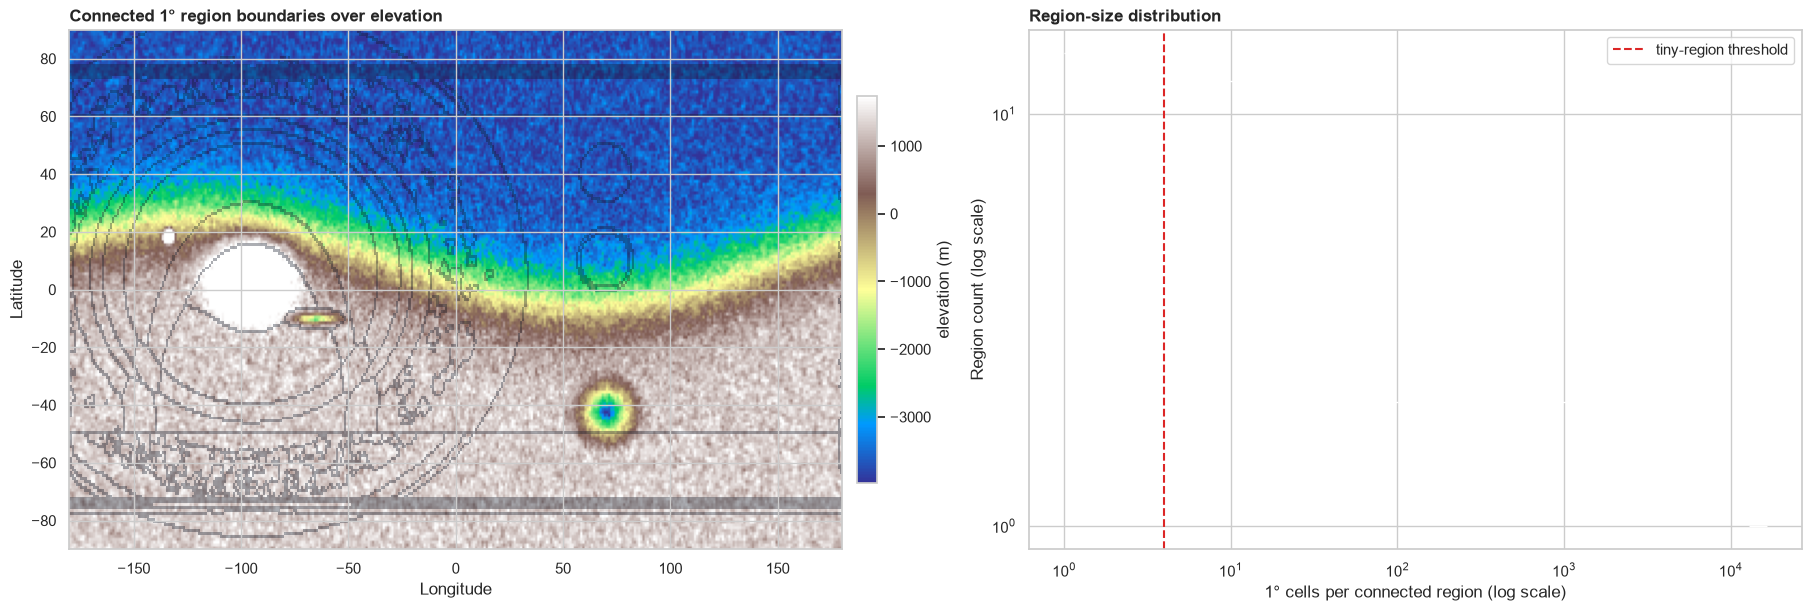

In [12]:
region_result_columns = [
    "region_id",
    "neutral_type",
    "selected_algorithm",
    "cluster_confidence",
    "limited_feature_evidence",
    "artifact_diagnostic_available",
    "artifact_warning",
    "anomaly_score",
    "is_anomaly_candidate",
    "is_reviewable_anomaly",
    "best_recipe_id",
    "best_candidate_label",
    "candidate_evidence_score",
]
region_cell_results_df = region_cells_df.merge(
    regions_df[region_result_columns],
    on="region_id",
    how="left",
    validate="many_to_one",
)


def raster_from_cells(frame: pd.DataFrame, value_column: str, shape: tuple[int, int], fill_value: float = np.nan) -> np.ndarray:
    raster = np.full(shape, fill_value, dtype=np.float64)
    raster[frame["row"].to_numpy(dtype=np.int32), frame["column"].to_numpy(dtype=np.int32)] = frame[value_column].to_numpy()
    return raster


def boundary_mask(labels: np.ndarray) -> np.ndarray:
    boundary = labels != np.roll(labels, -1, axis=1)
    boundary[:-1, :] |= labels[:-1, :] != labels[1:, :]
    return boundary


medium_cells = region_cell_results_df.loc[region_cell_results_df["scale"] == "medium_1deg"].copy()
medium_shape = grid_shape(medium_cells)
medium_labels = scale_label_rasters["medium_1deg"]
medium_elevation = raster_from_cells(medium_cells, "elevation_mean_m", medium_shape)
medium_boundaries = boundary_mask(medium_labels)

fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)
elevation_limits = np.nanpercentile(medium_elevation, [2, 98])
image = axes[0].imshow(
    medium_elevation,
    extent=[-180, 180, -90, 90],
    origin="upper",
    aspect="auto",
    cmap="terrain",
    vmin=elevation_limits[0],
    vmax=elevation_limits[1],
)
axes[0].imshow(
    np.where(medium_boundaries, 1.0, np.nan),
    extent=[-180, 180, -90, 90],
    origin="upper",
    aspect="auto",
    cmap=mcolors.ListedColormap(["#111827"]),
    alpha=0.35,
    interpolation="nearest",
)
axes[0].set_title("Connected 1° region boundaries over elevation", loc="left", fontweight="bold")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
plt.colorbar(image, ax=axes[0], fraction=0.025, pad=0.02, label="elevation (m)")

sns.histplot(
    data=regions_df.loc[regions_df["scale"] == "medium_1deg"],
    x="cell_count",
    bins=40,
    log_scale=(True, True),
    ax=axes[1],
    color="#2563EB",
)
axes[1].axvline(CFG.minimum_medium_region_cells, color="#DC2626", linestyle="--", label="tiny-region threshold")
axes[1].set_title("Region-size distribution", loc="left", fontweight="bold")
axes[1].set_xlabel("1° cells per connected region (log scale)")
axes[1].set_ylabel("Region count (log scale)")
axes[1].legend()
plt.show()

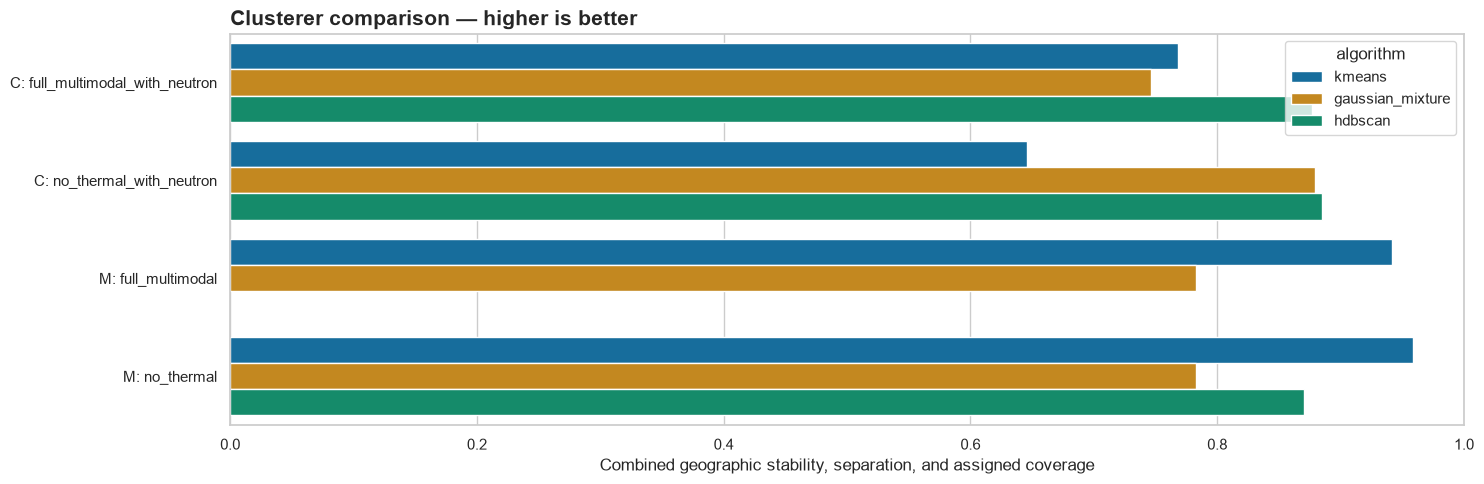

In [13]:
if len(model_comparison_df):
    comparison_plot = model_comparison_df.copy()
    comparison_plot["partition_short"] = comparison_plot["partition_id"].str.replace("medium_1deg__", "M: ", regex=False).str.replace("coarse_10deg__", "C: ", regex=False)
    plt.figure(figsize=(15, max(5, 0.55 * comparison_plot["partition_short"].nunique())))
    sns.barplot(
        data=comparison_plot,
        x="selection_score",
        y="partition_short",
        hue="algorithm",
        orient="h",
    )
    plt.xlim(0, 1)
    plt.xlabel("Combined geographic stability, separation, and assigned coverage")
    plt.ylabel("")
    plt.title("Clusterer comparison — higher is better", loc="left", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.show()

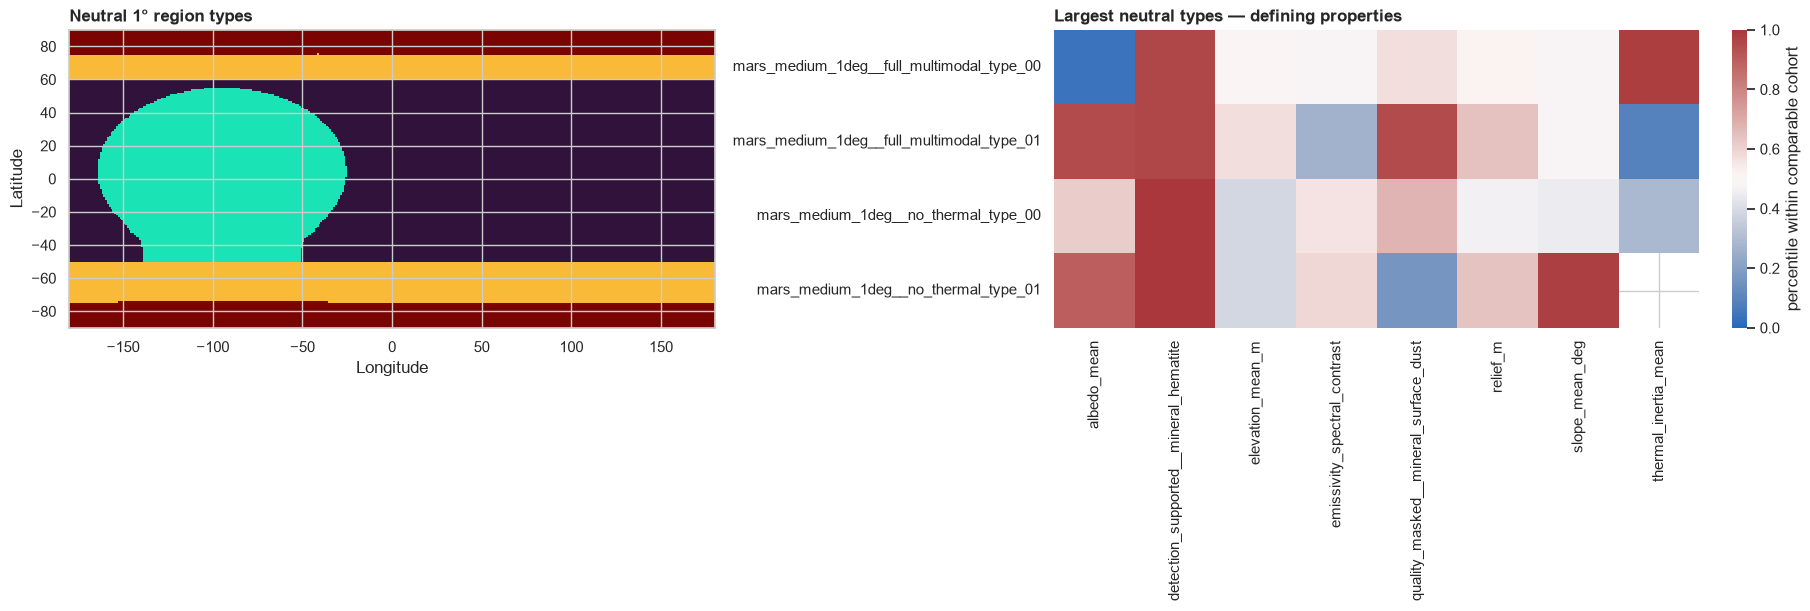

In [14]:
neutral_type_codes, neutral_type_names = pd.factorize(medium_cells["neutral_type"], sort=True)
medium_cells["neutral_type_code"] = neutral_type_codes
cluster_raster = raster_from_cells(medium_cells, "neutral_type_code", medium_shape, fill_value=-1)

fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)
axes[0].imshow(
    cluster_raster,
    extent=[-180, 180, -90, 90],
    origin="upper",
    aspect="auto",
    cmap="turbo",
    interpolation="nearest",
)
axes[0].set_title("Neutral 1° region types", loc="left", fontweight="bold")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

largest_types = (
    cluster_summary_df.loc[cluster_summary_df["scale"] == "medium_1deg"]
    .nlargest(20, "area_km2")["neutral_type"]
    .tolist()
)
key_profile_features = [
    "elevation_mean_m",
    "relief_m",
    "slope_mean_deg",
    "thermal_inertia_mean",
    "albedo_mean",
    "quality_masked__mineral_surface_dust",
    "detection_supported__mineral_high_ca_pyroxene",
    "detection_supported__mineral_hematite",
    "emissivity_spectral_contrast",
]
profile_heatmap = (
    cluster_profiles_df.loc[
        cluster_profiles_df["neutral_type"].isin(largest_types)
        & cluster_profiles_df["feature"].isin(key_profile_features)
    ]
    .pivot(index="neutral_type", columns="feature", values="partition_percentile")
    .reindex(index=largest_types)
)
if profile_heatmap.notna().any().any():
    sns.heatmap(
        profile_heatmap,
        cmap="vlag",
        center=0.5,
        vmin=0,
        vmax=1,
        ax=axes[1],
        cbar_kws={"label": "percentile within comparable cohort"},
    )
    axes[1].set_title("Largest neutral types — defining properties", loc="left", fontweight="bold")
    axes[1].set_xlabel("")
    axes[1].set_ylabel("")
else:
    axes[1].text(0.5, 0.5, "No common profile features", ha="center", va="center")
    axes[1].set_axis_off()
plt.show()

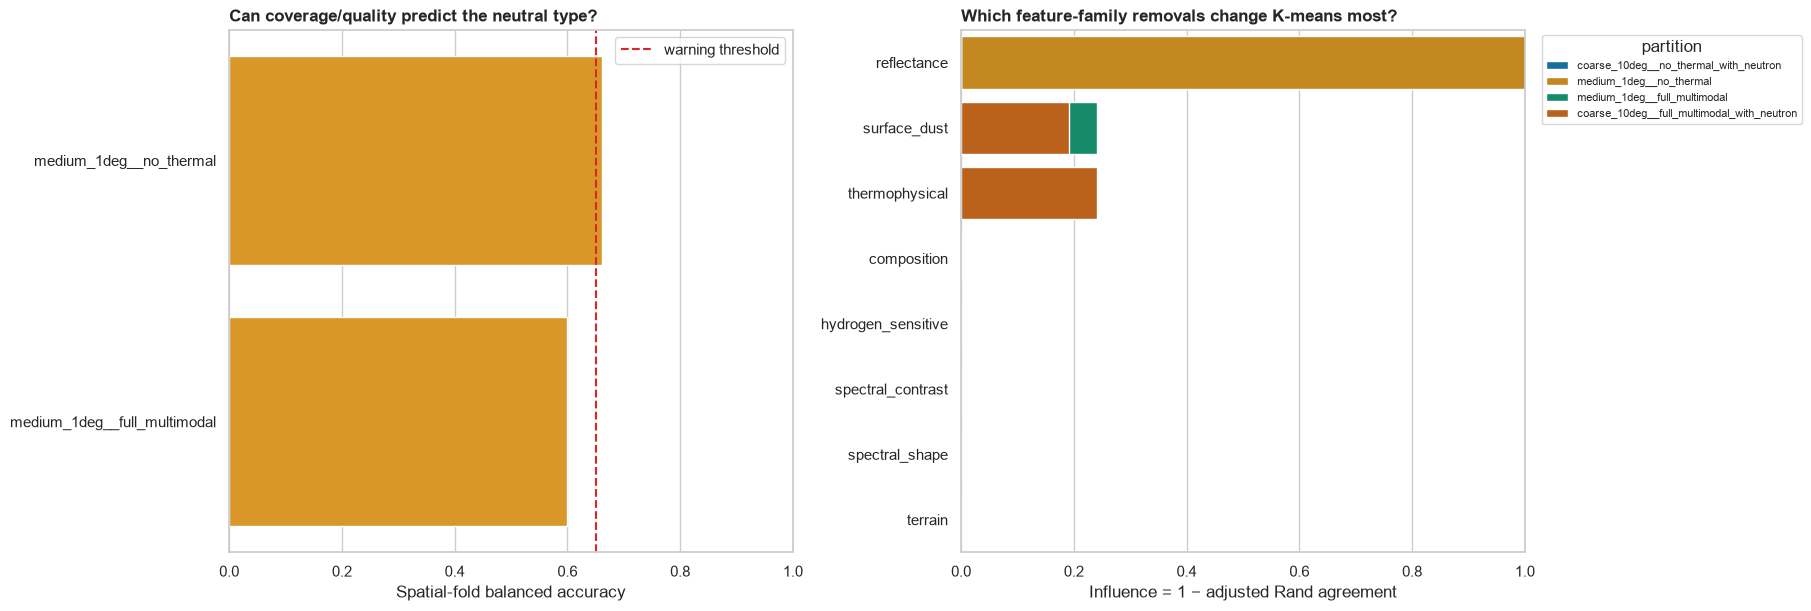

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)
if len(artifact_diagnostics_df):
    artifact_plot = artifact_diagnostics_df.sort_values("coverage_balanced_accuracy", ascending=False)
    sns.barplot(data=artifact_plot, x="coverage_balanced_accuracy", y="partition_id", color="#F59E0B", ax=axes[0])
    axes[0].axvline(CFG.artifact_warning_balanced_accuracy, color="#DC2626", linestyle="--", label="warning threshold")
    axes[0].set_xlim(0, 1)
    axes[0].set_title("Can coverage/quality predict the neutral type?", loc="left", fontweight="bold")
    axes[0].set_xlabel("Spatial-fold balanced accuracy")
    axes[0].set_ylabel("")
    axes[0].legend()
else:
    axes[0].text(0.5, 0.5, "Artifact diagnostic unavailable", ha="center", va="center")
    axes[0].set_axis_off()

if len(ablation_df):
    ablation_plot = ablation_df.nlargest(20, "influence")
    sns.barplot(data=ablation_plot, x="influence", y="removed_group", hue="partition_id", dodge=False, ax=axes[1])
    axes[1].set_xlim(0, 1)
    axes[1].set_title("Which feature-family removals change K-means most?", loc="left", fontweight="bold")
    axes[1].set_xlabel("Influence = 1 − adjusted Rand agreement")
    axes[1].set_ylabel("")
    axes[1].legend(fontsize=8, title="partition", bbox_to_anchor=(1.02, 1), loc="upper left")
else:
    axes[1].text(0.5, 0.5, "Ablation diagnostic unavailable", ha="center", va="center")
    axes[1].set_axis_off()
plt.show()

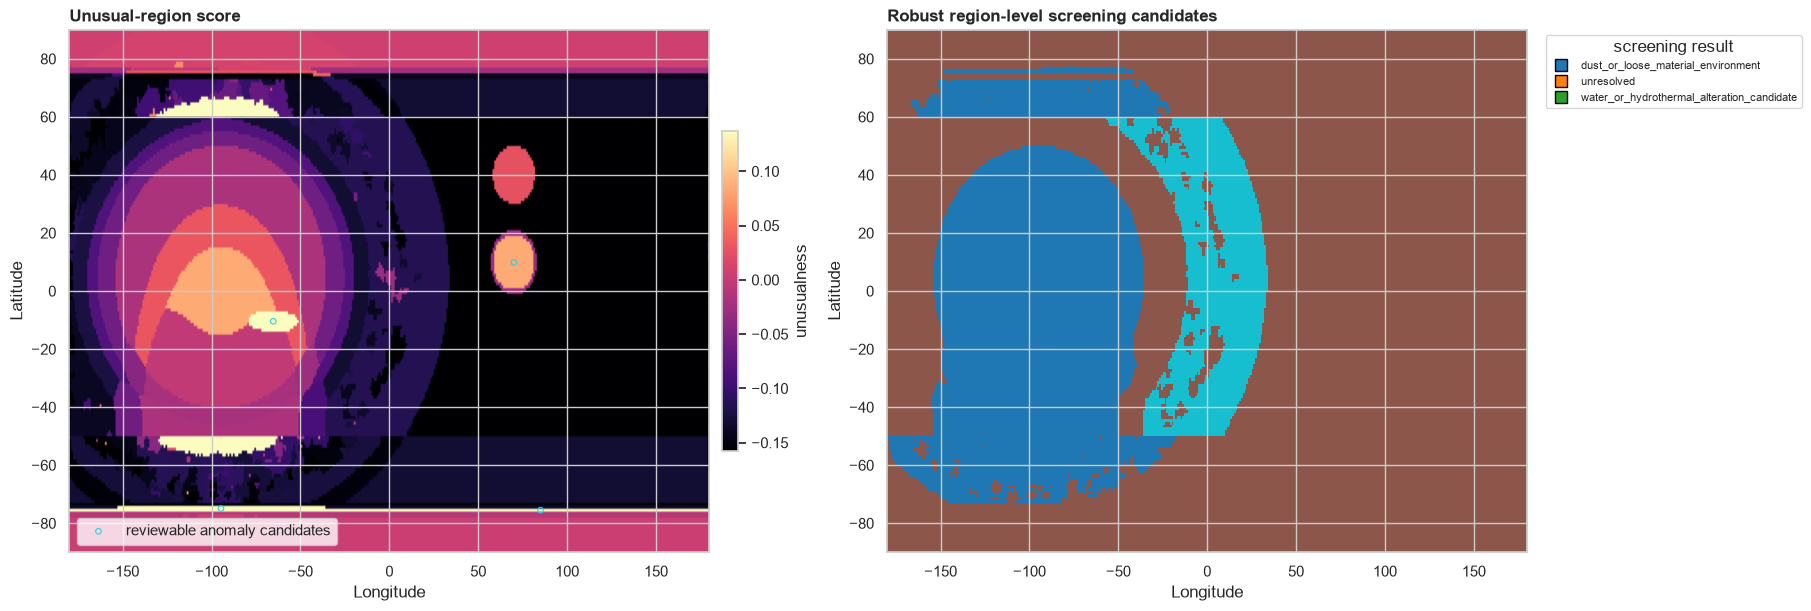

,region_id,scale,analysis_cohort,centroid_latitude,centroid_longitude,neutral_type,anomaly_score,artifact_warning,best_candidate_label
150,mars_medium_region_000110,medium_1deg,no_thermal,-74.924202,-94.720739,mars_medium_1deg__no_thermal_type_01,0.225583,False,NaN
78,mars_medium_region_000038,medium_1deg,full_multimodal,-10.428183,-65.324953,mars_medium_1deg__full_multimodal_type_01,0.195050,False,Dust-mantled or loose-material environment; ae...
159,mars_medium_region_000119,medium_1deg,no_thermal,-75.500000,85.000000,mars_medium_1deg__no_thermal_type_01,0.193812,False,NaN
22,mars_coarse_region_000023,coarse_10deg,no_thermal_with_neutron,-85.000000,180.000000,mars_coarse_10deg__no_thermal_with_neutron_unr...,0.114526,False,NaN
82,mars_medium_region_000042,medium_1deg,full_multimodal,9.860049,70.022303,mars_medium_1deg__full_multimodal_type_00,0.085204,False,NaN
2,mars_coarse_region_000003,coarse_10deg,full_multimodal_with_neutron,55.000000,-175.000000,mars_coarse_10deg__full_multimodal_with_neutro...,0.058432,False,NaN


In [16]:
anomaly_raster = raster_from_cells(medium_cells, "anomaly_score", medium_shape)
candidate_codes, candidate_names = pd.factorize(medium_cells["best_recipe_id"].fillna("unresolved"), sort=True)
medium_cells["candidate_code"] = candidate_codes
candidate_raster = raster_from_cells(medium_cells, "candidate_code", medium_shape, fill_value=-1)

fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)
anomaly_limits = np.nanpercentile(anomaly_raster, [2, 98])
anomaly_image = axes[0].imshow(
    anomaly_raster,
    extent=[-180, 180, -90, 90],
    origin="upper",
    aspect="auto",
    cmap="magma",
    vmin=anomaly_limits[0],
    vmax=anomaly_limits[1],
)
anomaly_regions = regions_df.loc[
    (regions_df["scale"] == "medium_1deg") & regions_df["is_reviewable_anomaly"]
]
axes[0].scatter(
    anomaly_regions["centroid_longitude"],
    anomaly_regions["centroid_latitude"],
    s=16,
    facecolors="none",
    edgecolors="#22D3EE",
    linewidths=0.8,
    label="reviewable anomaly candidates",
)
axes[0].set_title("Unusual-region score", loc="left", fontweight="bold")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].legend(loc="lower left")
plt.colorbar(anomaly_image, ax=axes[0], fraction=0.025, pad=0.02, label="unusualness")

candidate_image = axes[1].imshow(
    candidate_raster,
    extent=[-180, 180, -90, 90],
    origin="upper",
    aspect="auto",
    cmap="tab10",
    interpolation="nearest",
)
axes[1].set_title("Robust region-level screening candidates", loc="left", fontweight="bold")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
legend_handles = [
    plt.Line2D([0], [0], marker="s", color="none", markerfacecolor=plt.get_cmap("tab10")(index % 10), markersize=9, label=name)
    for index, name in enumerate(candidate_names)
]
axes[1].legend(handles=legend_handles, fontsize=8, title="screening result", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

top_anomalies_df = regions_df.loc[regions_df["is_reviewable_anomaly"]].nlargest(25, "anomaly_score")[
    [
        "region_id",
        "scale",
        "analysis_cohort",
        "centroid_latitude",
        "centroid_longitude",
        "neutral_type",
        "anomaly_score",
        "artifact_warning",
        "best_candidate_label",
    ]
]
display(top_anomalies_df)

## Export reproducible region and evidence artifacts

In [17]:
def json_compatible(value: Any) -> Any:
    if value is pd.NA:
        return None
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(f"Object of type {type(value).__name__} is not JSON serializable")


def labels_to_geojson(labels: np.ndarray, scale_name: str, region_id_lookup: dict[int, str], path: Path) -> None:
    cell_degrees = 1.0 if scale_name == "medium_1deg" else 10.0
    transform = from_origin(-180.0, 90.0, cell_degrees, cell_degrees)
    geometry_parts: defaultdict[int, list[list[Any]]] = defaultdict(list)
    for geometry, value in raster_shapes(
        labels.astype(np.int32),
        mask=labels > 0,
        transform=transform,
        connectivity=4,
    ):
        numeric_id = int(value)
        if geometry["type"] == "Polygon":
            geometry_parts[numeric_id].append(geometry["coordinates"])
        elif geometry["type"] == "MultiPolygon":
            geometry_parts[numeric_id].extend(geometry["coordinates"])
        else:
            raise ValueError(f"Unexpected raster polygon geometry: {geometry['type']}")
    features = []
    for numeric_id, polygons in geometry_parts.items():
        geometry = (
            {"type": "Polygon", "coordinates": polygons[0]}
            if len(polygons) == 1
            else {"type": "MultiPolygon", "coordinates": polygons}
        )
        features.append(
            {
                "type": "Feature",
                "properties": {"region_id": region_id_lookup[numeric_id], "scale": scale_name},
                "geometry": geometry,
            }
        )
    collection = {"type": "FeatureCollection", "features": features}
    path.write_text(json.dumps(collection, allow_nan=False, default=json_compatible), encoding="utf-8")


region_cells_export_columns = [
    "cell_id",
    "scale",
    "row",
    "column",
    "latitude",
    "longitude",
    "region_id",
    "neutral_type",
    "selected_algorithm",
    "cluster_confidence",
    "limited_feature_evidence",
    "artifact_diagnostic_available",
    "artifact_warning",
    "anomaly_score",
    "is_anomaly_candidate",
    "is_reviewable_anomaly",
    "best_recipe_id",
    "best_candidate_label",
    "candidate_evidence_score",
]
region_cell_results_df[region_cells_export_columns].to_parquet(REGION_DIR / "mars_region_cells.parquet", index=False, compression="zstd")
regions_df.to_parquet(REGION_DIR / "mars_regions.parquet", index=False, compression="zstd")
adjacency_df.to_parquet(REGION_DIR / "mars_region_adjacency.parquet", index=False, compression="zstd")
cluster_summary_df.to_parquet(REGION_DIR / "mars_neutral_type_summary.parquet", index=False, compression="zstd")
cluster_profiles_df.to_parquet(REGION_DIR / "mars_neutral_type_profiles.parquet", index=False, compression="zstd")
process_evidence_df.to_parquet(REGION_DIR / "mars_process_evidence.parquet", index=False, compression="zstd")
top_anomalies_df.to_csv(REPORT_DIR / "top_anomaly_candidates.csv", index=False)
control_sites_df.to_csv(REPORT_DIR / "reference_locations.csv", index=False)
model_comparison_df.to_csv(REPORT_DIR / "cluster_model_comparison.csv", index=False)
artifact_diagnostics_df.to_csv(REPORT_DIR / "coverage_artifact_diagnostics.csv", index=False)
artifact_importance_df.to_csv(REPORT_DIR / "coverage_artifact_feature_importance.csv", index=False)
ablation_df.to_csv(REPORT_DIR / "feature_group_ablation.csv", index=False)
quality_correction_df.to_csv(REPORT_DIR / "quality_effect_correction.csv", index=False)

(REPORT_DIR / "partition_manifest.json").write_text(
    json.dumps(partition_manifest, indent=2, allow_nan=False, default=json_compatible),
    encoding="utf-8",
)
(REPORT_DIR / "process_recipe_registry.json").write_text(
    json.dumps(PROCESS_RECIPES, indent=2, allow_nan=False, default=json_compatible),
    encoding="utf-8",
)

np.savez_compressed(
    REGION_DIR / "mars_region_label_rasters.npz",
    medium_1deg=scale_label_rasters["medium_1deg"],
    coarse_10deg=scale_label_rasters["coarse_10deg"],
)

for scale_name, labels in scale_label_rasters.items():
    lookup = (
        regions_df.loc[regions_df["scale"] == scale_name]
        .set_index("region_numeric_id")["region_id"]
        .to_dict()
    )
    labels_to_geojson(labels, scale_name, lookup, REGION_DIR / f"mars_{scale_name}_regions.geojson")

for partition_id, model in segmentation_models.items():
    joblib.dump(model, MODEL_DIR / f"segmentation_{re.sub(r'[^a-zA-Z0-9_-]+', '_', partition_id)}.joblib")
for partition_id, model in selected_models.items():
    joblib.dump(model, MODEL_DIR / f"clustering_{re.sub(r'[^a-zA-Z0-9_-]+', '_', partition_id)}.joblib")
for partition_id, model in anomaly_models.items():
    joblib.dump(model, MODEL_DIR / f"anomaly_{re.sub(r'[^a-zA-Z0-9_-]+', '_', partition_id)}.joblib")

supported_evidence = process_evidence_df.loc[process_evidence_df["status"] == "supported"]
withheld_evidence = process_evidence_df.loc[process_evidence_df["status"].str.startswith("withheld")]
artifact_warning_partitions = sorted(
    regions_df.loc[regions_df["artifact_warning"], "partition_id"].dropna().unique().tolist()
)
fragmentation_warning_partitions = sorted(
    regions_df.groupby("partition_id", observed=True)["is_tiny_region"]
    .mean()
    .loc[lambda series: series > 0.20]
    .index.tolist()
)
minimum_reference_matches = max(1, math.ceil(len(control_sites_df) * 0.70))
match_col = "has_expected_recipe_match" if "has_expected_recipe_match" in control_sites_df.columns else "expected_candidate_match"
reference_site_expected_matches = int(control_sites_df[match_col].fillna(False).sum())
earth_filter_handoff_ready = bool(
    preparation_summary.get("status") == "complete_clean"
    and not artifact_warning_partitions
    and not fragmentation_warning_partitions
    and reference_site_expected_matches >= minimum_reference_matches
)
summary = {
    "status": "complete_ready_for_handoff" if earth_filter_handoff_ready else "complete_not_ready_for_handoff",
    "run_started_utc": RUN_STARTED_UTC,
    "run_finished_utc": datetime.now(timezone.utc).isoformat(),
    "configuration": asdict(CFG),
    "input_root": str(INPUT_ROOT),
    "preparation_status": preparation_summary.get("status"),
    "input_cells": int(len(cells_df)),
    "connected_regions": int(len(regions_df)),
    "connected_regions_by_scale": regions_df.groupby("scale", observed=True)["region_id"].nunique().astype(int).to_dict(),
    "neutral_types": int(regions_df["neutral_type"].nunique()),
    "neutral_types_by_partition": regions_df.groupby("partition_id", observed=True)["neutral_type"].nunique().astype(int).to_dict(),
    "anomaly_candidates": int(regions_df["is_anomaly_candidate"].sum()),
    "reviewable_anomaly_candidates": int(regions_df["is_reviewable_anomaly"].sum()),
    "supported_process_screenings": int(len(supported_evidence)),
    "withheld_process_screenings": int(len(withheld_evidence)),
    "reference_site_expected_matches": reference_site_expected_matches,
    "reference_site_count": int(len(control_sites_df)),
    "minimum_reference_matches_for_handoff": minimum_reference_matches,
    "artifact_warning_partitions": artifact_warning_partitions,
    "fragmentation_warning_partitions": fragmentation_warning_partitions,
    "earth_filter_handoff_ready": earth_filter_handoff_ready,
    "important_limits": [
        "Neutral clusters are recurring property combinations, not proven causes.",
        "Process recipes are screening hypotheses and retain missing confirmation evidence.",
        "Static global products cannot establish present activity.",
        "Hydrogen-sensitive neutron evidence does not uniquely identify water ice.",
        "TES orbital-track coverage can influence composition patterns and must be checked in artifact diagnostics.",
        "Targeted high-resolution data are required before final interpretation of shortlisted regions.",
    ],
    "outputs": {
        "region_cells": str(REGION_DIR / "mars_region_cells.parquet"),
        "regions": str(REGION_DIR / "mars_regions.parquet"),
        "adjacency": str(REGION_DIR / "mars_region_adjacency.parquet"),
        "medium_geojson": str(REGION_DIR / "mars_medium_1deg_regions.geojson"),
        "coarse_geojson": str(REGION_DIR / "mars_coarse_10deg_regions.geojson"),
        "neutral_type_summary": str(REGION_DIR / "mars_neutral_type_summary.parquet"),
        "process_evidence": str(REGION_DIR / "mars_process_evidence.parquet"),
        "model_comparison": str(REPORT_DIR / "cluster_model_comparison.csv"),
        "artifact_diagnostics": str(REPORT_DIR / "coverage_artifact_diagnostics.csv"),
        "quality_correction": str(REPORT_DIR / "quality_effect_correction.csv"),
        "ablation": str(REPORT_DIR / "feature_group_ablation.csv"),
        "reference_locations": str(REPORT_DIR / "reference_locations.csv"),
        "recipes": str(REPORT_DIR / "process_recipe_registry.json"),
    },
}
(REPORT_DIR / "run_summary.json").write_text(
    json.dumps(summary, indent=2, allow_nan=False, default=json_compatible),
    encoding="utf-8",
)

summary_markdown = f"""# Mars region-discovery run summary

- Status: **{summary['status']}**
- Input cells: **{summary['input_cells']:,}**
- Connected regions: **{summary['connected_regions']:,}**
- Neutral types: **{summary['neutral_types']}**
- Raw unusual-region candidates: **{summary['anomaly_candidates']:,}**
- Reviewable unusual-region candidates: **{summary['reviewable_anomaly_candidates']:,}**
- Robust region-level process/environment screening matches: **{summary['supported_process_screenings']:,}**
- Evidence matches withheld for artifact, limited-feature, or tiny-region risk: **{summary['withheld_process_screenings']:,}**
- Reference-site expected matches: **{summary['reference_site_expected_matches']}/{summary['reference_site_count']}**
- Partitions with a coverage-artifact warning: **{len(summary['artifact_warning_partitions'])}**
- Partitions with more than 20% unresolved tiny regions: **{len(summary['fragmentation_warning_partitions'])}**
- Ready to hand robust candidates to Earth filtering: **{summary['earth_filter_handoff_ready']}**

## Correct interpretation

The output is a shortlist of connected regions, recurring neutral types, anomalies, and evidence-based **candidates**. It is not a catalog of confirmed or active processes. Any shortlisted candidate must be refined with the detailed instruments named in its missing-evidence field.
"""
(REPORT_DIR / "run_summary.md").write_text(summary_markdown, encoding="utf-8")
display(Markdown(summary_markdown))

# Synchronize key artifacts to repository processed/ and reports/
import shutil
repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
repo_processed = repo_root / "processed"
repo_reports = repo_root / "reports"
repo_processed.mkdir(parents=True, exist_ok=True)
repo_reports.mkdir(parents=True, exist_ok=True)

sync_files = [
    (REGION_DIR / "mars_region_cells.parquet", repo_processed / "mars_region_cells.parquet"),
    (REGION_DIR / "mars_regions.parquet", repo_processed / "mars_regions.parquet"),
    (REGION_DIR / "mars_region_adjacency.parquet", repo_processed / "mars_region_adjacency.parquet"),
    (REGION_DIR / "mars_neutral_type_summary.parquet", repo_processed / "mars_neutral_type_summary.parquet"),
    (REGION_DIR / "mars_neutral_type_profiles.parquet", repo_processed / "mars_neutral_type_profiles.parquet"),
    (REGION_DIR / "mars_process_evidence.parquet", repo_processed / "mars_process_evidence.parquet"),
    (REGION_DIR / "mars_medium_1deg_regions.geojson", repo_processed / "mars_regions.geojson"),
    (REGION_DIR / "mars_medium_1deg_regions.geojson", repo_processed / "mars_medium_1deg_regions.geojson"),
    (REPORT_DIR / "run_summary.json", repo_reports / "mars_run_summary.json"),
    (REPORT_DIR / "process_recipe_registry.json", repo_reports / "mars_process_recipe_registry.json"),
    (REPORT_DIR / "reference_locations.csv", repo_reports / "mars_reference_locations.csv"),
    (REPORT_DIR / "top_anomaly_candidates.csv", repo_reports / "mars_top_anomaly_candidates.csv"),
]
for src, dst in sync_files:
    if src.exists():
        shutil.copy2(src, dst)

# Generate unified Mars-to-Earth Filter Specifications
mars_earth_filter_specs = {
    "mafic_volcanic_terrain": {
        "target_body": "Mars (Syrtis Major / Olympus Mons flanks)",
        "mission_test_focus": "Basaltic volcanism mobility, rover wheel wear on sharp vesicular lava, seismic sensor deployment",
        "earth_analog_requirements": {
            "volcanic_basalt_bedrock": True,
            "pyroxene_olivine_spectral_signature": True,
            "max_vegetation_ndvi": 0.12,
            "slope_deg_max": 15.0
        },
        "benchmark_analog_sites": [
            "Hawaii Volcanic Basalt Fields (Mauna Loa)",
            "Iceland Basaltic Sands & Volcanic Highlands",
            "Canary Islands (Lanzarote Volcanic Fields)",
            "Morocco Anti-Atlas Volcanic Terranes"
        ]
    },
    "water_hydrothermal_alteration": {
        "target_body": "Mars (Jezero Crater / Meridiani Planum / Mawrth Vallis)",
        "mission_test_focus": "Biosignature detection, phyllosilicate and sulfate drilling, ancient lacustrine sampling",
        "earth_analog_requirements": {
            "hydrothermal_alteration_minerals": True,
            "sulfates_or_clays_presence": True,
            "aridity_index_max": 0.25,
            "max_vegetation_ndvi": 0.08
        },
        "benchmark_analog_sites": [
            "Rio Tinto (Spain - iron/sulfate extremophiles)",
            "Dallol Geothermal Springs (Ethiopia)",
            "Pilbara Ancient Strelley Pool Formation (Australia)",
            "Zagora / Ouarzazate Lacustrine Strata (Morocco)"
        ]
    },
    "hyper_arid_aeolian_dunes": {
        "target_body": "Mars (Gale Crater Dunes / Medusae Fossae Formation)",
        "mission_test_focus": "Aeolian sand traversal, rover slip and trenching hazard, atmospheric dust abrasion",
        "earth_analog_requirements": {
            "hyper_arid_climate": True,
            "active_aeolian_dunes": True,
            "sand_slip_angle_deg": [28.0, 36.0],
            "max_vegetation_ndvi": 0.02
        },
        "benchmark_analog_sites": [
            "Atacama Desert (Yungay Hyper-Arid Core, Chile)",
            "Erg Chebbi / Merzouga Sand Dunes (Morocco)",
            "Namib Sand Sea (Namibia)",
            "Mojave Desert Dumont Dunes (California)"
        ]
    },
    "subsurface_permafrost_cryosphere": {
        "target_body": "Mars (Planum Boreum / Utopia Planitia Ground Ice)",
        "mission_test_focus": "Subsurface ice-penetrating radar, cryogenic core drilling, polygonal ground navigation",
        "earth_analog_requirements": {
            "permafrost_ground_ice": True,
            "mean_annual_temp_c_max": -12.0,
            "patterned_ground_polygons": True,
            "max_vegetation_ndvi": 0.05
        },
        "benchmark_analog_sites": [
            "Devon Island Haughton Impact Crater (Canadian High Arctic)",
            "University Valley & Beacon Valley (Antarctica)",
            "Svalbard Permafrost Terrains (Norway)"
        ]
    }
}
spec_path = repo_reports / "mars_earth_filter_specifications.json"
spec_path.write_text(json.dumps(mars_earth_filter_specs, indent=2), encoding="utf-8")
print(f"Mars-Earth Filter Specifications exported to {spec_path}")


# Mars region-discovery run summary

- Status: **complete_not_ready_for_handoff**
- Input cells: **65,448**
- Connected regions: **227**
- Neutral types: **10**
- Raw unusual-region candidates: **7**
- Reviewable unusual-region candidates: **6**
- Robust region-level process/environment screening matches: **0**
- Evidence matches withheld for artifact, limited-feature, or tiny-region risk: **32**
- Reference-site expected matches: **1/7**
- Partitions with a coverage-artifact warning: **0**
- Partitions with more than 20% unresolved tiny regions: **0**
- Ready to hand robust candidates to Earth filtering: **False**

## Correct interpretation

The output is a shortlist of connected regions, recurring neutral types, anomalies, and evidence-based **candidates**. It is not a catalog of confirmed or active processes. Any shortlisted candidate must be refined with the detailed instruments named in its missing-evidence field.


Mars-Earth Filter Specifications exported to C:\Users\ordik\OneDrive\Documents\NASA-HACK\reports\mars_earth_filter_specifications.json


## Handoff

First check `earth_filter_handoff_ready` in the run summary. If it is false, the reported segmentation or reference-control gate must be fixed before using the candidates as Earth filters. If it is true, review the artifact warnings, stable neutral types, anomaly shortlist, and process-evidence gaps. Retrieve CTX/HiRISE, CRISM, THEMIS, SHARAD, or repeat observations only for shortlisted regions whose interpretation needs those measurements. Validated Mars evidence can then be translated into measurable Earth filters.